In [22]:
# ==== CELL 0: environment check (run right after a kernel restart) ====
import importlib.metadata as md, traceback, os, sys
print('=== CELL 0 ===')
print('python :', sys.executable, '| cwd:', os.getcwd())
for p in ['numpy', 'pandas', 'torch', 'scipy', 'matplotlib', 'scikit-learn', 'scikit-image', 'openslide-python', 'pillow']:
    try:
        print(f'{p:18s}', md.version(p))
    except md.PackageNotFoundError:
        print(f'{p:18s} not installed')
try:
    import pandas as pd
    print('\npandas import OK', pd.__version__)
except Exception:
    print('\nFIRST pandas import error:'); traceback.print_exc()
import torch
print('CUDA available:', torch.cuda.is_available(),
      '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else '-')
if torch.cuda.is_available():
    try:
        torch.zeros(2, device='cuda').sum().item(); print('CUDA kernel test: OK')
    except Exception as ex:
        print('CUDA kernel test FAILED:', ex)

=== CELL 0 ===
python : /N/u/vpjoshi/Quartz/miniconda3/envs/gecko_clean/bin/python3.11 | cwd: /N/slate/vpjoshi/Envs/WSIToolsEnv/GECKO/GECKO
numpy              2.4.3
pandas             2.3.3
torch              2.5.1+cu121
scipy              1.15.3
matplotlib         3.11.0
scikit-learn       1.8.0
scikit-image       0.26.0
openslide-python   1.4.3
pillow             12.1.1

pandas import OK 2.3.3
CUDA available: True | GPU: Tesla V100-PCIE-32GB
CUDA kernel test: OK


In [23]:
# ==== CELL 1: paths & config (760 + 790 cohort, Protocol B encoders) ====
import os, sys, glob, json, pickle
import numpy as np, pandas as pd, torch

BASE       = '/N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir'
MODEL_ROOT = f'{BASE}/gecko_runs_v3'
RUN_NAME   = 'protB_fold{fold}'                       # checkpoint folder per fold
features_deep_path = f'{BASE}/deep_features_3.pth'
features_path      = f'{BASE}/concept_prior_3.csv'
dataset_dict_path  = f'{BASE}/all_dict_3.pickle'
all_list_path      = f'{BASE}/all_list_3.pickle'
label_csv_path     = f'{BASE}/BCR_label_master_csv.csv'
split_path         = f'{BASE}/splits_4/protocolB_rotating'   # fold0.csv, fold1.csv, fold2.csv
CONCEPT_JSON   = '/N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/patch_prompts_merged_touse.json'
GECKO_CODE_DIR = '/N/slate/vpjoshi/Envs/WSIToolsEnv/GECKO/GECKO'
OUT_DIR        = f'{MODEL_ROOT}/figures_cam'

# ---- CONFIG (confirmed against cells 2-6) ----
FOLDS       = [0, 1, 2]
LABEL_COL   = 'event'                    # to confirm in cell 5
PATCH       = 448                        # to confirm in cell 11
PATCH_REGEX = r'^(.*)_(\d+)_(\d+)_stitched\d*\.\w+$'
TOP_K       = 10
cohort_of   = lambda k: '790' if str(k).startswith('0790-') else '760'

os.makedirs(OUT_DIR, exist_ok=True)
sys.path.insert(0, GECKO_CODE_DIR)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('=== CELL 1 ===  device:', DEVICE)
for name, p in [('deep', features_deep_path), ('concept_prior', features_path), ('dataset_dict', dataset_dict_path),
                ('all_list', all_list_path), ('labels', label_csv_path), ('splits', split_path),
                ('concept_json', CONCEPT_JSON), ('batched_simil', os.path.join(GECKO_CODE_DIR, 'batched_simil.py')),
                ('out_dir', OUT_DIR)]:
    print(f'{name:15s} exists={os.path.exists(p)}  {p}')
for f in FOLDS:
    d = f'{MODEL_ROOT}/{RUN_NAME.format(fold=f)}'
    print(f'fold {f}: checkpoint={os.path.exists(d + "/checkpoint.pth")} | concept_minmax={os.path.exists(d + "/concept_minmax.npz")} '
          f'| split csv={os.path.exists(f"{split_path}/fold{f}.csv")}')

=== CELL 1 ===  device: cuda
deep            exists=True  /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/deep_features_3.pth
concept_prior   exists=True  /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/concept_prior_3.csv
dataset_dict    exists=True  /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/all_dict_3.pickle
all_list        exists=True  /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/all_list_3.pickle
labels          exists=True  /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/BCR_label_master_csv.csv
splits          exists=True  /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/splits_4/protocolB_rotating
concept_json    exists=True  /N/project/prostate_cancer_ai/Ven

In [25]:
# ==== CELL 2: concept JSON structure ====
with open(CONCEPT_JSON) as f:
    cj = json.load(f)

def show(o, depth=0, max_items=40, max_depth=3):
    pad = '  ' * depth
    if depth > max_depth:
        print(pad + '...'); return
    if isinstance(o, dict):
        print(f'{pad}dict[{len(o)}]')
        for k, v in list(o.items())[:max_items]:
            if isinstance(v, (dict, list)):
                print(f'{pad}- {k!r}:'); show(v, depth + 1, max_items, max_depth)
            else:
                print(f'{pad}- {k!r}: {str(v)[:100]!r}')
    elif isinstance(o, list):
        print(f'{pad}list[{len(o)}]')
        for v in o[:max_items]:
            if isinstance(v, (dict, list)):
                show(v, depth + 1, max_items, max_depth)
            else:
                print(f'{pad}  {str(v)[:100]!r}')

print('=== CELL 2 ===')
show(cj)

=== CELL 2 ===
dict[2]
- 'Gland':
  dict[11]
  - 'Gleason Pattern 3': 'Discrete well-formed glands; small infiltrative glands; variable gland size; glands separated by str'
  - 'Gleason Pattern 4': 'Fused glands; poorly formed glands; glomeruloid glands; irregular merging glandular structures.'
  - 'Cribriform Glands': 'Cribriform architecture; sieve-like gland; multiple punched-out lumens; large expanded gland nest.'
  - 'Complex Papillary Architecture': 'Papillary fronds; fibrovascular cores; complex branching papillae; tall columnar pseudostratified ce'
  - 'Gleason Pattern 5': 'Solid sheets of tumor cells; cords of tumor cells; single infiltrating tumor cells; solid nests; sma'
  - 'Comedonecrosis': 'Central comedonecrosis; necrotic debris in gland center; karyorrhectic nuclear dust; solid tumor nes'
  - 'Nuclear Atypia': 'Enlarged nuclei; hyperchromatic nuclei; round to oval nuclei; irregular nuclear membranes; crowded a'
  - 'Prominent Nucleoli': 'Prominent nucleoli; large eosino

In [26]:
# ==== CELL 3: concept_prior.csv header + match to JSON ====
cp_head = pd.read_csv(features_path, nrows=3)
with open(features_path) as f:
    n_rows = sum(1 for _ in f) - 1
print('=== CELL 3 ===  rows:', n_rows, '| cols:', cp_head.shape[1])
json_names = [(g, k) for g in ('Gland', 'Stroma') for k in cj[g]]
norm_ = lambda s: s.split(';')[0].strip().replace('_', ' ').lower()
jlook = {k.replace('_', ' ').lower(): g for g, k in json_names}
for i, c in enumerate(cp_head.columns):
    grp = jlook.get(norm_(c), '??') if i > 0 else ''
    print(f'{i:2d}  {grp:6s}  {c[:100]}')
cols = list(cp_head.columns[1:])
print('\nall CSV concepts found in JSON:', all(norm_(c) in jlook for c in cols),
      '| CSV order == JSON order:', [norm_(c) for c in cols] == [k.replace('_', ' ').lower() for _, k in json_names])
print('\nfirst index values (patch names):')
for v in cp_head.iloc[:, 0]:
    print('  ', v)
print('\nfirst row values:', np.round(cp_head.iloc[0, 1:].values.astype(float), 4))

=== CELL 3 ===  rows: 160913 | cols: 26
 0          Unnamed: 0
 1  Gland   Gleason Pattern 3; Discrete well-formed glands; small infiltrative glands; variable gland size; glan
 2  Gland   Gleason Pattern 4; Fused glands; poorly formed glands; glomeruloid glands; irregular merging glandul
 3  Gland   Cribriform Glands; Cribriform architecture; sieve-like gland; multiple punched-out lumens; large exp
 4  Gland   Complex Papillary Architecture; Papillary fronds; fibrovascular cores; complex branching papillae; t
 5  Gland   Gleason Pattern 5; Solid sheets of tumor cells; cords of tumor cells; single infiltrating tumor cell
 6  Gland   Comedonecrosis; Central comedonecrosis; necrotic debris in gland center; karyorrhectic nuclear dust;
 7  Gland   Nuclear Atypia; Enlarged nuclei; hyperchromatic nuclei; round to oval nuclei; irregular nuclear memb
 8  Gland   Prominent Nucleoli; Prominent nucleoli; large eosinophilic nucleoli; macronucleoli; visible red nucl
 9  Gland   Amphophilic Cytoplasm

In [27]:
# ==== CELL 4: dataset dict + patch list + slide-alignment check ====
import re
with open(dataset_dict_path, 'rb') as f:
    dd = pickle.load(f)
dd = {str(k): (int(v[0]), int(v[1])) for k, v in dd.items()}
print('=== CELL 4 ===  n slides:', len(dd), '| first 3:', list(dd.items())[:3])
print('max end index:', max(v[1] for v in dd.values()))
sizes = pd.Series({k: v[1] - v[0] for k, v in dd.items()}).sort_values()
print('\npatches per slide:\n', sizes.describe().round(1).to_string())
print('\n5 largest slides:\n', sizes.tail(5).to_string())
with open(all_list_path, 'rb') as f:
    all_list = [str(p) for p in pickle.load(f)]
print('\nall_list:', len(all_list), '| first:', all_list[:2])

# every row in a slide's range must be a patch of that slide
pat = re.compile(PATCH_REGEX)
sid = np.array([pat.match(os.path.basename(p)).group(1) for p in all_list])
bad = sum(int((sid[s:e] != k).sum()) for k, (s, e) in dd.items())
print('rows whose patch belongs to another slide:', bad, '(must be 0)')

lab = pd.read_csv(label_csv_path)
lab = lab.loc[:, ~lab.columns.str.startswith('Unnamed')]
print('\nlabel csv columns:', lab.columns.tolist())
lab['cohort'] = lab['case_id'].map(cohort_of)
print(lab.groupby('cohort')[LABEL_COL].agg(['count', 'sum']).rename(columns={'count': 'slides', 'sum': 'BCR+'}).to_string())
print('dict keys == label case_ids:', set(dd) == set(lab['case_id'].astype(str)))

=== CELL 4 ===  n slides: 128 | first 3: [('0790-99_A4_converted', (0, 3300)), ('SN21-4556_A3', (3300, 3454)), ('0790-105_AX', (3454, 3943))]
max end index: 160913

patches per slide:
 count     128.0
mean     1257.1
std       973.5
min       130.0
25%       603.0
50%      1014.5
75%      1662.8
max      5859.0

5 largest slides:
 S22-2527_A8              3521
0790-18_A4_converted     3966
0790-64_A5_converted     4198
0790-75_C8_converted     5341
0790-76_B10_converted    5859

all_list: 160913 | first: ['/N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/790_stichedup_normpatches_new_10052026/0790-99_A4_converted_50560_121152_stitched448.png', '/N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/790_stichedup_normpatches_new_10052026/0790-99_A4_converted_31744_119808_stitched448.png']
rows whose patch belongs to another slide: 0 (must be 0)

label csv columns: ['case_id', 'event', 'split']
        slides  BCR+
cohort              
76

In [28]:
# ==== CELL 5: fold splits (Protocol B) + consistency with each run's train_slides.json ====
print('=== CELL 5 ===')
test_of = {}
for fold in FOLDS:
    df_s = pd.read_csv(f'{split_path}/fold{fold}.csv')
    df_s = df_s.loc[:, ~df_s.columns.str.startswith('Unnamed')]
    print(f'\nfold{fold}: shape={df_s.shape} cols={df_s.columns.tolist()}')
    for c in df_s.columns:
        if df_s[c].nunique() <= 5:
            print(f'   {c}: {df_s[c].value_counts().to_dict()}')
    if fold == FOLDS[0]:
        print(df_s.head(3).to_string())
    tsj = f'{MODEL_ROOT}/{RUN_NAME.format(fold=fold)}/train_slides.json'
    tr_json = json.load(open(tsj))
    tr_json = tr_json if isinstance(tr_json, list) else list(tr_json.values())[0] if isinstance(tr_json, dict) else tr_json
    print(f'   train_slides.json: {type(tr_json).__name__} of {len(tr_json)} | first: {list(tr_json)[:2]}')
    test_of[fold] = df_s

=== CELL 5 ===

fold0: shape=(128, 4) cols=['case_id', 'event', 'cohort', 'split']
   event: {0: 105, 1: 23}
   cohort: {790: 81, 760: 47}
   split: {'train': 85, 'test': 43}
                case_id  event  cohort  split
0  0790-99_A4_converted      0     790  train
1          SN21-4556_A3      0     760  train
2           0790-105_AX      0     790  train
   train_slides.json: list of 85 | first: ['0790-99_A4_converted', 'SN21-4556_A3']

fold1: shape=(128, 4) cols=['case_id', 'event', 'cohort', 'split']
   event: {0: 105, 1: 23}
   cohort: {790: 81, 760: 47}
   split: {'train': 85, 'test': 43}
   train_slides.json: list of 85 | first: ['0790-99_A4_converted', 'SN21-4556_A3']

fold2: shape=(128, 4) cols=['case_id', 'event', 'cohort', 'split']
   event: {0: 105, 1: 23}
   cohort: {790: 81, 760: 47}
   split: {'train': 86, 'test': 42}
   train_slides.json: list of 86 | first: ['0790-72_A9_converted', 'S21-26543_C6']


In [29]:
# ==== CELL 6: MILNet output shapes on one slide (fold-0 checkpoint, fold-0 concept_minmax) ====
import batched_simil as mil
run0 = f'{MODEL_ROOT}/{RUN_NAME.format(fold=FOLDS[0])}'
mm = np.load(f'{run0}/concept_minmax.npz')
print('=== CELL 6 === concept_minmax keys:', {k: mm[k].shape for k in mm.files})
cfg = json.load(open(f'{run0}/config.json')); print('config top_k:', cfg.get('top_k'))

deep = torch.load(features_deep_path, map_location='cpu', weights_only=True).float()
cp   = pd.read_csv(features_path).set_index('Unnamed: 0')
assert list(cp.index[:5]) == all_list[:5] and len(cp) == len(all_list)
X_raw = cp.values.astype(np.float32); C = X_raw.shape[1]
print('deep:', tuple(deep.shape), '| concepts:', X_raw.shape)

key  = sizes.index[len(sizes) // 2]; s, e = dd[key]
k_mn = [k for k in mm.files if 'min' in k.lower()][0]; k_mx = [k for k in mm.files if 'max' in k.lower()][0]
mn, mx = mm[k_mn].reshape(-1), mm[k_mx].reshape(-1)
print(f'using min key {k_mn!r}, max key {k_mx!r} | shapes {mn.shape} {mx.shape}')
Xn = (X_raw[s:e] - mn) / (mx - mn + 1e-6)
print('normalised range on this slide: %.3f .. %.3f' % (Xn.min(), Xn.max()))

b = mil.BClassifier(input_size=C, input_size_deep=deep.shape[1], top_k=TOP_K).to(DEVICE)
m = mil.MILNet(b).to(DEVICE)
sd = torch.load(f'{run0}/checkpoint.pth', map_location=DEVICE, weights_only=False)
if isinstance(sd, dict) and not any(torch.is_tensor(v) for v in sd.values()):
    print('checkpoint dict keys:', list(sd.keys()))
    sd = next(sd[k] for k in ['state_dict', 'model', 'model_state_dict', 'net'] if k in sd)
print('load:', m.load_state_dict(sd, strict=False))
m.eval()
with torch.no_grad():
    out = m(torch.from_numpy(Xn)[None].to(DEVICE), deep[s:e][None].to(DEVICE))
for n, o in zip(['bag_features', 'out1', 'out2', 'bag_features_deep', 'A_feat', 'A_patch'], out):
    print(f'{n:18s}', tuple(o.shape) if torch.is_tensor(o) else type(o).__name__)
A_patch = out[5].reshape(-1).float().cpu(); A_feat = out[4].reshape(-1).float().cpu()
print(f'\nslide={key} | n_patches={e - s}')
print('A_patch: sum=%.4f min=%.2e max=%.2e (uniform = %.2e) | max/mean = %.2f'
      % (A_patch.sum(), A_patch.min(), A_patch.max(), 1 / (e - s), A_patch.max() / A_patch.mean()))
print('A_feat :', np.round(A_feat.numpy(), 4))

=== CELL 6 === concept_minmax keys: {'c_min': (25,), 'c_max': (25,), 'concept_names': (25,)}
config top_k: 10
deep: (160913, 512) | concepts: (160913, 25)
using min key 'c_min', max key 'c_max' | shapes (25,) (25,)
normalised range on this slide: 0.030 .. 0.996
load: <All keys matched successfully>
bag_features       (1, 25)
out1               (1, 25)
out2               (1, 25)
bag_features_deep  (1, 512)
A_feat             (1, 25)
A_patch            (1, 1015, 1)

slide=S22-8095_B7 | n_patches=1015
A_patch: sum=1.0000 min=5.30e-04 max=9.61e-03 (uniform = 9.85e-04) | max/mean = 9.75
A_feat : [0.5286 0.5047 0.5732 0.6509 0.7362 0.7309 0.5624 0.5859 0.6751 0.747
 0.6603 0.6866 0.7227 0.8148 0.5053 0.6231 0.5939 0.6834 0.4429 0.7898
 0.7243 0.5179 0.6643 0.7874 0.4298]


In [30]:
# ==== CELL 7: out-of-fold concept scores + attention for every patch ====
# Each slide is scored ONLY by the Protocol B encoder for which it was a test slide,
# with that run's saved train-only min-max (concept_minmax.npz = exactly what GECKO trained with).
import batched_simil as mil

SHORT = np.array([c.split(';')[0].strip() for c in cp.columns])
gl_set = {k.replace('_', ' ').lower() for k in cj['Gland']}
st_set = {k.replace('_', ' ').lower() for k in cj['Stroma']}
GROUP = np.array(['Glandular' if s.lower() in gl_set else 'Stromal' if s.lower() in st_set else '??' for s in SHORT])
assert (GROUP != '??').all()

parsed = [pat.match(os.path.basename(p)) for p in all_list]
px = np.array([int(q.group(2)) for q in parsed]); py = np.array([int(q.group(3)) for q in parsed])

def load_gecko(run_dir):
    b = mil.BClassifier(input_size=C, input_size_deep=deep.shape[1], top_k=TOP_K).to(DEVICE)
    m = mil.MILNet(b).to(DEVICE)
    sd = torch.load(f'{run_dir}/checkpoint.pth', map_location=DEVICE, weights_only=False)
    if isinstance(sd, dict) and not any(torch.is_tensor(v) for v in sd.values()):
        sd = next(sd[k] for k in ['state_dict', 'model', 'model_state_dict', 'net'] if k in sd)
    msg = m.load_state_dict(sd, strict=False)
    assert not msg.missing_keys and not msg.unexpected_keys, msg
    return m.eval()

N = len(X_raw)
norm = np.full((N, C), np.nan, np.float32); att = np.full(N, np.nan, np.float32)
BAG_C, BAG_D, slides, seen = {}, {}, [], []
for fold in FOLDS:
    run = f'{MODEL_ROOT}/{RUN_NAME.format(fold=fold)}'
    split = pd.read_csv(f'{split_path}/fold{fold}.csv')
    split['case_id'] = split['case_id'].astype(str)
    tr = set(split.loc[split.split == 'train', 'case_id']); te = split.loc[split.split == 'test', 'case_id'].tolist()
    tsj = json.load(open(f'{run}/train_slides.json'))
    assert set(map(str, tsj['train'])) == tr, f'fold {fold}: json train != split train'
    assert set(map(str, tsj['test_never_seen'])) == set(te), f'fold {fold}: json test_never_seen != split test'
    assert not (tr & set(te)), f'fold {fold}: train/test overlap'
    lab_ = dict(zip(split.case_id, split[LABEL_COL]))
    mmz = np.load(f'{run}/concept_minmax.npz', allow_pickle=True)
    assert [str(x).split(';')[0].strip() for x in mmz['concept_names']] == list(SHORT), 'minmax concept order differs'
    mn, mx = mmz['c_min'].reshape(-1), mmz['c_max'].reshape(-1)
    m = load_gecko(run)
    with torch.no_grad():
        for k in te:
            s, e = dd[k]
            Xn = ((X_raw[s:e] - mn) / (mx - mn + 1e-6)).astype(np.float32)
            out = m(torch.from_numpy(Xn)[None].to(DEVICE), deep[s:e][None].to(DEVICE))
            a_patch = out[5].reshape(-1).float().cpu().numpy(); a_feat = out[4].reshape(-1).float().cpu().numpy()
            norm[s:e], att[s:e] = Xn, a_patch
            BAG_C[k] = out[0].reshape(-1).float().cpu().numpy(); BAG_D[k] = out[3].reshape(-1).float().cpu().numpy()
            slides.append(dict(slide=k, cohort=cohort_of(k), fold=fold, bcr=int(lab_[k]), start=s, end=e, n_patches=e - s,
                               att_ratio=float(a_patch.max() / a_patch.mean()),
                               att_top10_share=float(np.sort(a_patch)[::-1][:TOP_K].sum()),
                               **{f'afeat_{j}': float(a_feat[j]) for j in range(C)}))
            seen.append(k)
    print(f'fold {fold}: train slides={len(tr)} (json OK) | test slides={len(te)} (json OK) | BCR+ in test={sum(int(lab_[k]) for k in te)}')
    del m; torch.cuda.empty_cache()

assert sorted(seen) == sorted(dd) and len(seen) == len(set(seen)), 'some slides not scored exactly once'
assert not np.isnan(att).any()
df_slides = pd.DataFrame(slides).sort_values('start').reset_index(drop=True)
np.savez_compressed(f'{OUT_DIR}/oof_patch_scores.npz', norm=norm, att=att, px=px, py=py,
                    short=SHORT, group=GROUP, paths=np.array(all_list))
np.savez_compressed(f'{OUT_DIR}/oof_bag_features.npz', slide=df_slides.slide.values,
                    bag_c=np.stack([BAG_C[k] for k in df_slides.slide]), bag_d=np.stack([BAG_D[k] for k in df_slides.slide]))
df_slides.to_csv(f'{OUT_DIR}/oof_slides.csv', index=False)

print(f'\n=== CELL 7 === scored {len(df_slides)} slides | BCR+ {df_slides.bcr.sum()} | BCR- {(df_slides.bcr == 0).sum()}')
print('concepts:', {str(k): int(v) for k, v in zip(*np.unique(GROUP, return_counts=True))})
print('\nattention flatness (A_patch max/mean; 1.0 = flat) and share of attention on top-10 patches:')
print(df_slides.groupby('cohort')[['att_ratio', 'att_top10_share', 'n_patches']].describe()
      .loc[:, (slice(None), ['min', '50%', 'max'])].round(3).to_string())
print('\nA_feat (mean over slides) range: %.3f .. %.3f' % tuple(df_slides[[f"afeat_{j}" for j in range(C)]].mean().agg(['min', 'max'])))

fold 0: train slides=85 (json OK) | test slides=43 (json OK) | BCR+ in test=8
fold 1: train slides=85 (json OK) | test slides=43 (json OK) | BCR+ in test=8
fold 2: train slides=86 (json OK) | test slides=42 (json OK) | BCR+ in test=7

=== CELL 7 === scored 128 slides | BCR+ 23 | BCR- 105
concepts: {'Glandular': 11, 'Stromal': 14}

attention flatness (A_patch max/mean; 1.0 = flat) and share of attention on top-10 patches:
       att_ratio                att_top10_share               n_patches                
             min    50%     max             min    50%    max       min     50%     max
cohort                                                                                 
760        3.191  9.140  16.584           0.011  0.060  0.232     154.0  1122.0  3521.0
790        3.221  8.968  16.859           0.007  0.065  0.294     130.0   963.0  5859.0

A_feat (mean over slides) range: 0.426 .. 0.770


In [31]:
# ==== CELL 8: cohort-level averaged CAM statistics (cohort-adjusted, patient level primary) ====
from scipy import stats
from sklearn.metrics import roc_auc_score

z = np.load(f'{OUT_DIR}/oof_patch_scores.npz', allow_pickle=False)
norm, att, SHORT, GROUP = z['norm'], z['att'], z['short'], z['group']
df_slides = pd.read_csv(f'{OUT_DIR}/oof_slides.csv')
C = norm.shape[1]; AF = df_slides[[f'afeat_{j}' for j in range(C)]].values
y = df_slides.bcr.values.astype(int); coh = df_slides.cohort.astype(str).values
COHORTS = sorted(np.unique(coh), reverse=True)            # ['790', '760']
N_SELECT, B_BOOT, N_PERM = 5, 2000, 10000
rng = np.random.default_rng(0)

def cams(defn, agg):
    """per-slide mean CAM (n_slides x C) + per-patch CAM rows and their slide index"""
    M, rows, owner = np.zeros((len(df_slides), C)), [], []
    for i, r in df_slides.iterrows():
        s, e = int(r.start), int(r.end)
        A = X_raw[s:e] if defn == 'raw' else norm[s:e] * AF[i]
        if agg == 'top10':
            A = A[np.argsort(-att[s:e])[:TOP_K]]
        M[i] = A.mean(0); rows.append(A); owner.append(np.full(len(A), i))
    return M, np.vstack(rows).astype(np.float32), np.concatenate(owner)

def cohort_z(M, c_of):
    Z = np.empty_like(M, dtype=np.float64)
    for c in COHORTS:
        k = c_of == c; Z[k] = (M[k] - M[k].mean(0)) / (M[k].std(0, ddof=1) + 1e-12)
    return Z

def hedges(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(0, ddof=1) + (nb - 1) * b.var(0, ddof=1)) / (na + nb - 2))
    return (a.mean(0) - b.mean(0)) / (sp + 1e-12) * (1 - 3 / (4 * (na + nb) - 9))

def bh(p):
    p = np.asarray(p); o = np.argsort(p); q = p[o] * len(p) / np.arange(1, len(p) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]; out = np.empty_like(q); out[o] = np.minimum(q, 1); return out

# within-cohort label permutations and stratified bootstrap indices (shared by all four versions)
PY = np.tile(y, (N_PERM, 1))
for c in COHORTS:
    idx = np.where(coh == c)[0]
    PY[:, idx] = rng.permuted(np.tile(y[idx], (N_PERM, 1)), axis=1)
strata = [np.where((coh == c) & (y == b_))[0] for c in COHORTS for b_ in (0, 1)]
BOOT = [np.concatenate([rng.choice(s_, len(s_), replace=True) for s_ in strata]) for _ in range(B_BOOT)]
n1, n0 = y.sum(), (1 - y).sum()

RES, SLIDE_CAM = {}, {}
for defn in ['raw', 'gecko']:
    for agg in ['all', 'top10']:
        tag = f'{defn}_{agg}'
        M, P, own = cams(defn, agg); Z = cohort_z(M, coh); SLIDE_CAM[tag] = M
        d_obs = Z[y == 1].mean(0) - Z[y == 0].mean(0)
        d_null = (PY @ Z) / n1 - ((1 - PY) @ Z) / n0
        p_perm = (1 + (np.abs(d_null) >= np.abs(d_obs) - 1e-12).sum(0)) / (1 + N_PERM)
        d_boot = np.array([Z[b_][y[b_] == 1].mean(0) - Z[b_][y[b_] == 0].mean(0) for b_ in BOOT])
        Pz = cohort_z(P, coh[own]); yp = y[own]
        df = pd.DataFrame(dict(concept=SHORT, group=GROUP, col=np.arange(C), delta=d_obs,
                               lo=np.percentile(d_boot, 2.5, 0), hi=np.percentile(d_boot, 97.5, 0),
                               g=hedges(Z[y == 1], Z[y == 0]),
                               auc=[roc_auc_score(y, Z[:, j]) for j in range(C)],
                               p_perm=p_perm, q=bh(p_perm), patch_g=hedges(Pz[yp == 1], Pz[yp == 0])))
        for c in COHORTS:
            k = coh == c
            df[f'delta_{c}'] = Z[k & (y == 1)].mean(0) - Z[k & (y == 0)].mean(0)
            df[f'g_{c}'] = hedges(Z[k & (y == 1)], Z[k & (y == 0)])
        df['same_sign'] = np.sign(df[f'delta_{COHORTS[0]}']) == np.sign(df[f'delta_{COHORTS[1]}'])
        df['rank_in_group'] = df.groupby('group').g.transform(lambda s_: s_.abs().rank(ascending=False, method='first')).astype(int)
        df['selected'] = df.rank_in_group <= N_SELECT
        df.to_csv(f'{OUT_DIR}/averaged_cam_stats_{tag}.csv', index=False); RES[tag] = df

np.savez_compressed(f'{OUT_DIR}/slide_cam_matrices.npz', slide=df_slides.slide.values, y=y, cohort=coh,
                    **{k: v for k, v in SLIDE_CAM.items()})
PRIMARY = 'raw_all'
st_df = RES[PRIMARY]
SELECTED = {g_: st_df[(st_df.group == g_) & st_df.selected].sort_values('rank_in_group').col.tolist() for g_ in ['Glandular', 'Stromal']}
json.dump({g_: [int(c) for c in v] for g_, v in SELECTED.items()}, open(f'{OUT_DIR}/selected_concepts.json', 'w'))

pd.set_option('display.width', 250)
print(f'=== CELL 8 === patients: BCR+ {n1} vs BCR- {n0} | cohort-z per slide | {N_PERM} within-cohort perms | {B_BOOT} boots')
print(f'\nPRIMARY [{PRIMARY}: raw concept scores, all patches]')
cols = ['group', 'concept', 'delta', 'lo', 'hi', 'g', 'auc', 'p_perm', 'q', 'delta_790', 'delta_760', 'same_sign', 'patch_g', 'selected']
print(st_df.sort_values(['group', 'rank_in_group'])[cols].to_string(index=False, float_format=lambda v: f'{v:.3f}'))
print('\nconcepts with q < 0.05 / q < 0.10 per version:',
      {k: (int((v.q < 0.05).sum()), int((v.q < 0.10).sum())) for k, v in RES.items()})
print('Spearman of g vs primary:', {k: round(stats.spearmanr(RES[PRIMARY].g, v.g).correlation, 2) for k, v in RES.items() if k != PRIMARY})
print('SELECTED:', {g_: [str(SHORT[c]) for c in v] for g_, v in SELECTED.items()})

=== CELL 8 === patients: BCR+ 23 vs BCR- 105 | cohort-z per slide | 10000 within-cohort perms | 2000 boots

PRIMARY [raw_all: raw concept scores, all patches]
    group                        concept  delta     lo     hi      g   auc  p_perm     q  delta_790  delta_760  same_sign  patch_g  selected
Glandular      Single Luminal Cell Layer -0.688 -1.119 -0.313 -0.710 0.301   0.003 0.025     -0.518     -1.064       True   -0.137      True
Glandular              Gleason Pattern 4 -0.606 -1.134 -0.135 -0.620 0.315   0.010 0.062     -0.525     -0.788       True   -0.255      True
Glandular          Amphophilic Cytoplasm -0.498 -0.853 -0.154 -0.505 0.342   0.032 0.135     -0.575     -0.339       True   -0.235      True
Glandular              Cribriform Glands -0.402 -0.875  0.029 -0.405 0.399   0.083 0.210     -0.262     -0.709       True   -0.153      True
Glandular              Gleason Pattern 3 -0.384 -0.887  0.091 -0.386 0.392   0.098 0.210     -0.364     -0.432       True   -0.183      

In [32]:
# ==== CELL 8b: concept-specific effect or slide-wide shift? ====
M = SLIDE_CAM['raw_all']; Z = cohort_z(M, coh)

def test(Zm):
    d = Zm[y == 1].mean(0) - Zm[y == 0].mean(0)
    dn = (PY @ Zm) / n1 - ((1 - PY) @ Zm) / n0
    p = (1 + (np.abs(dn) >= np.abs(d) - 1e-12).sum(0)) / (1 + N_PERM)
    return d, hedges(Zm[y == 1], Zm[y == 0]), p

print('=== CELL 8b ===')
# 1) slide-wide level: mean raw cosine over all 25 concepts (cohort-z)
glob = cohort_z(M.mean(1, keepdims=True), coh)
d, g, p = test(glob)
print(f'[1] slide mean cosine (all 25 concepts): delta={d[0]:+.3f}  g={g[0]:+.3f}  p_perm={p[0]:.4f}  AUC={roc_auc_score(y, glob[:, 0]):.3f}')

# 2) first principal component of the cohort-z concept profile
Zc = Z - Z.mean(0); _, sv, vt = np.linalg.svd(Zc, full_matrices=False)
pc1 = Zc @ vt[0]; pc1 *= np.sign(np.corrcoef(pc1, glob[:, 0])[0, 1])
d, g, p = test(pc1[:, None])
print(f'[2] PC1: {100 * sv[0]**2 / (sv**2).sum():.1f}% of variance | loadings same sign: {(np.sign(vt[0]) == np.sign(vt[0]).mean().round()).mean():.0%} '
      f'| corr with [1]: {np.corrcoef(pc1, glob[:, 0])[0, 1]:.2f} | g={g[0]:+.3f} p_perm={p[0]:.4f} AUC={roc_auc_score(y, pc1):.3f}')

# 3) relative profile: each concept minus the slide's mean over all concepts (what stands out in that slide)
R = Z - Z.mean(1, keepdims=True)
d_r, g_r, p_r = test(R)
rel = pd.DataFrame(dict(group=GROUP, concept=SHORT, g_abs=st_df.g.values, q_abs=st_df.q.values,
                        g_rel=g_r, p_rel=p_r, q_rel=bh(p_r)))
for c in COHORTS:
    k = coh == c; rel[f'g_rel_{c}'] = hedges(R[k & (y == 1)], R[k & (y == 0)])
rel['same_sign_rel'] = np.sign(rel[f'g_rel_{COHORTS[0]}']) == np.sign(rel[f'g_rel_{COHORTS[1]}'])
rel = rel.sort_values('g_rel'); rel.to_csv(f'{OUT_DIR}/averaged_cam_stats_raw_all_relative.csv', index=False)
print('\n[3] relative concept profile (slide-wide level removed):')
print(rel.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
print('\nq_rel < 0.05 / < 0.10:', int((rel.q_rel < 0.05).sum()), '/', int((rel.q_rel < 0.10).sum()),
      '| Spearman g_abs vs g_rel: %.2f' % stats.spearmanr(rel.g_abs, rel.g_rel).correlation)

=== CELL 8b ===
[1] slide mean cosine (all 25 concepts): delta=-0.665  g=-0.684  p_perm=0.0048  AUC=0.311
[2] PC1: 32.4% of variance | loadings same sign: 0% | corr with [1]: 0.31 | g=+0.226 p_perm=0.3217 AUC=0.557

[3] relative concept profile (slide-wide level removed):
    group                        concept  g_abs  q_abs  g_rel  p_rel  q_rel  g_rel_790  g_rel_760  same_sign_rel
  Stromal                  Myxoid Stroma -0.844  0.010 -0.610  0.008  0.067     -0.571     -0.675           True
  Stromal                    Eosinophils -0.731  0.022 -0.490  0.035  0.219     -0.336     -0.824           True
Glandular              Gleason Pattern 4 -0.620  0.062 -0.455  0.057  0.244     -0.329     -0.749           True
Glandular      Single Luminal Cell Layer -0.710  0.025 -0.436  0.059  0.244     -0.253     -0.843           True
Glandular          Amphophilic Cytoplasm -0.505  0.135 -0.273  0.245  0.510     -0.363     -0.064           True
  Stromal          Increased Vascularity -0.532  

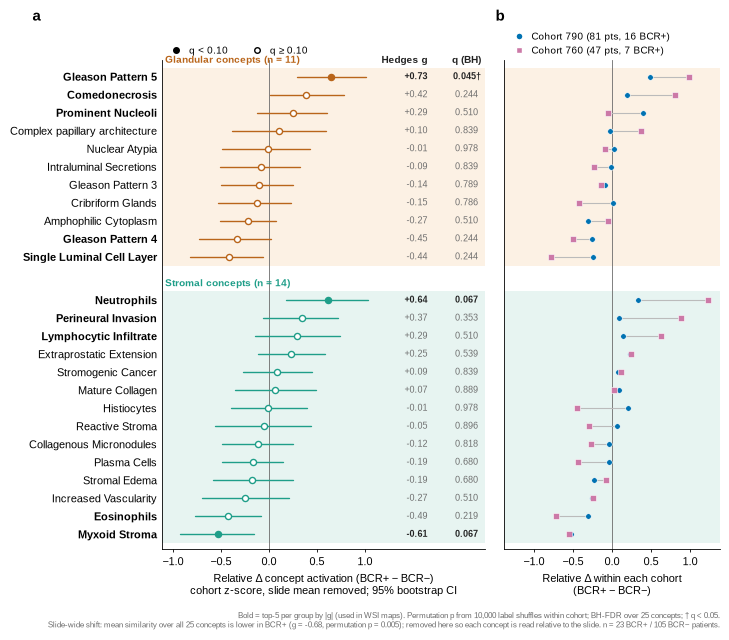

=== CELL 9 === saved: /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/fig_averaged_CAM_relative.png, /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/fig_averaged_CAM_relative.pdf, /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/fig_averaged_CAM_relative.svg
SELECTED (relative): {'Glandular': ['Gleason Pattern 5', 'Gleason Pattern 4', 'Single Luminal Cell Layer', 'Comedonecrosis', 'Prominent Nucleoli'], 'Stromal': ['Neutrophils', 'Myxoid Stroma', 'Eosinophils', 'Perineural Invasion', 'Lymphocytic Infiltrate']}
    group                   concept  delta     lo     hi      g     q  delta_790  delta_760
Glandular         Gleason Pattern 5  0.647  0.294  1.010  0.727 0.045      0.491      0.991
Glandular         Gleason Pattern 4 -0.330 -0.724  0.025 -0.455 

In [33]:
# ==== CELL 9: Figure — cohort-level relative concept activation (panel B) ====
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D

# ---- relative-profile statistics (PRIMARY): cohort-z per concept, then slide mean over concepts removed ----
M = SLIDE_CAM['raw_all']; Z = cohort_z(M, coh); R = Z - Z.mean(1, keepdims=True)
d_r, g_r, p_r = test(R); q_r = bh(p_r)
d_boot = np.array([R[b_][y[b_] == 1].mean(0) - R[b_][y[b_] == 0].mean(0) for b_ in BOOT])
rel = pd.DataFrame(dict(concept=SHORT, group=GROUP, col=np.arange(C), delta=d_r,
                        lo=np.percentile(d_boot, 2.5, 0), hi=np.percentile(d_boot, 97.5, 0),
                        g=g_r, p_perm=p_r, q=q_r))
for c in COHORTS:
    k = coh == c
    rel[f'delta_{c}'] = R[k & (y == 1)].mean(0) - R[k & (y == 0)].mean(0)
    rel[f'g_{c}'] = hedges(R[k & (y == 1)], R[k & (y == 0)])
rel['same_sign'] = np.sign(rel[f'delta_{COHORTS[0]}']) == np.sign(rel[f'delta_{COHORTS[1]}'])
rel['rank_in_group'] = rel.groupby('group').g.transform(lambda s_: s_.abs().rank(ascending=False, method='first')).astype(int)
rel['selected'] = rel.rank_in_group <= N_SELECT
rel.to_csv(f'{OUT_DIR}/averaged_cam_stats_raw_all_relative.csv', index=False)
SELECTED = {g_: rel[(rel.group == g_) & rel.selected].sort_values('rank_in_group').col.tolist() for g_ in ['Glandular', 'Stromal']}
json.dump({g_: [int(c) for c in v] for g_, v in SELECTED.items()}, open(f'{OUT_DIR}/selected_concepts.json', 'w'))
glob = cohort_z(M.mean(1, keepdims=True), coh); d_gl, g_gl, p_gl = test(glob)

# ---- style ----
FONT = next((f for f in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans']
             if any(f == x.name for x in font_manager.fontManager.ttflist)), 'DejaVu Sans')
mpl.rcParams.update({'font.family': FONT, 'font.size': 8, 'axes.linewidth': 0.6,
                     'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'xtick.major.size': 2.5, 'ytick.major.size': 0,
                     'svg.fonttype': 'none', 'pdf.fonttype': 42, 'ps.fonttype': 42})
COL = {'Glandular': '#B9651A', 'Stromal': '#1F9E89', 'band_Glandular': '#FCF1E4', 'band_Stromal': '#E7F4F1',
       '790': '#0072B2', '760': '#CC79A7', 'ink': '#222222', 'muted': '#6B6B6B'}
MARK = {'790': 'o', '760': 's'}
LABEL = {'Complex Papillary Architecture': 'Complex papillary architecture'}
Q_FILL = 0.10

d = rel.copy(); blocks, yy, ypos, GAP = [], 0.9, {}, 1.4
for g_ in ['Glandular', 'Stromal']:
    sub = d[d.group == g_].sort_values('delta', ascending=False); start = yy
    for c in sub.col: ypos[c] = yy; yy += 1
    blocks.append((g_, start - 0.5, yy - 0.5, len(sub))); yy += GAP
d['y'] = d.col.map(ypos)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 6.3), sharey=True,
                               gridspec_kw=dict(width_ratios=[1.5, 1], wspace=0.07))
for ax in (ax1, ax2):
    for g_, y0, y1, n in blocks:
        ax.axhspan(y0, y1, color=COL[f'band_{g_}'], zorder=0, lw=0)
    ax.spines[['top', 'right']].set_visible(False); ax.axvline(0, color=COL['muted'], lw=0.6, zorder=1)

# panel a: pooled relative delta with bootstrap CI + g, q columns
xmax = np.abs(d[['lo', 'hi']].values).max() * 1.08
for _, r in d.iterrows():
    filled = r.q < Q_FILL
    ax1.plot([r.lo, r.hi], [r.y, r.y], color=COL[r.group], lw=1.0, zorder=2, solid_capstyle='round')
    ax1.plot(r.delta, r.y, 'o', ms=4.4, mec=COL[r.group], mew=1.0, mfc=COL[r.group] if filled else 'white', zorder=3)
    for xt, txt in [(xmax * 1.48, f'{r.g:+.2f}'), (xmax * 1.98, f'{r.q:.3f}' + ('†' if r.q < 0.05 else ' '))]:
        ax1.text(xt, r.y, txt, ha='right', va='center', fontsize=6.8,
                 color=COL['ink'] if r.q < Q_FILL else COL['muted'], fontweight='bold' if r.q < Q_FILL else 'normal')
for xt, h in [(xmax * 1.48, 'Hedges g'), (xmax * 1.98, 'q (BH)')]:
    ax1.text(xt, blocks[0][1] - 0.15, h, ha='right', va='bottom', fontsize=7, fontweight='bold', color=COL['ink'])
ax1.set_xlim(-xmax, xmax * 2.02)
ax1.set_xticks([t for t in ax1.get_xticks() if -xmax <= t <= xmax])
ax1.set_yticks(d.y); ax1.set_yticklabels([LABEL.get(c, c) for c in d.concept])
for lab_, (_, r) in zip(ax1.get_yticklabels(), d.iterrows()):
    lab_.set_fontweight('bold' if r.selected else 'normal')
for g_, y0, y1, n in blocks:
    ax1.text(0.01, y0 - 0.15, f'{g_} concepts (n = {n})', transform=ax1.get_yaxis_transform(), ha='left', va='bottom',
             fontsize=7.5, fontweight='bold', color=COL[g_])
ax1.set_xlabel('Relative Δ concept activation (BCR+ − BCR−)\ncohort z-score, slide mean removed; 95% bootstrap CI')
ax1.legend(handles=[Line2D([], [], marker='o', ls='', mfc='k', mec='k', ms=4, label=f'q < {Q_FILL:.2f}'),
                    Line2D([], [], marker='o', ls='', mfc='white', mec='k', ms=4, label=f'q ≥ {Q_FILL:.2f}')],
           loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=7, handletextpad=0.3, borderaxespad=0.1)
ax1.set_ylim(blocks[-1][2] + 0.3, 0)

# panel b: relative delta within each cohort
for _, r in d.iterrows():
    ax2.plot([r[f'delta_{COHORTS[0]}'], r[f'delta_{COHORTS[1]}']], [r.y, r.y], color='#BBBBBB', lw=0.8, zorder=2)
    for c in COHORTS:
        ax2.plot(r[f'delta_{c}'], r.y, MARK[c], ms=4.0, mfc=COL[c], mec='white', mew=0.4, zorder=3)
xm2 = np.abs(d[[f'delta_{c}' for c in COHORTS]].values).max() * 1.12
ax2.set_xlim(-xm2, xm2); ax2.tick_params(axis='y', length=0)
ax2.set_xlabel('Relative Δ within each cohort\n(BCR+ − BCR−)')
cn = {c: (int((coh == c).sum()), int(y[coh == c].sum())) for c in COHORTS}
ax2.legend(handles=[Line2D([], [], marker=MARK[c], ls='', mfc=COL[c], mec='white', ms=5,
                           label=f'Cohort {c} ({cn[c][0]} pts, {cn[c][1]} BCR+)') for c in COHORTS],
           loc='lower left', bbox_to_anchor=(0, 1.0), ncol=1, frameon=False, fontsize=7, handletextpad=0.3, borderaxespad=0.1)

for ax, letter, xoff in [(ax1, 'a', -0.40), (ax2, 'b', -0.04)]:
    ax.text(xoff, 1.075, letter, transform=ax.transAxes, fontsize=11, fontweight='bold', va='bottom')
fig.text(0.99, 0.006,
         f'Bold = top-{N_SELECT} per group by |g| (used in WSI maps). Permutation p from {N_PERM:,} label shuffles within cohort; '
         f'BH-FDR over 25 concepts; † q < 0.05.\nSlide-wide shift: mean similarity over all 25 concepts is lower in BCR+ '
         f'(g = {g_gl[0]:+.2f}, permutation p = {p_gl[0]:.3f}); removed here so each concept is read relative to the slide. '
         f'n = {n1} BCR+ / {n0} BCR− patients.',
         ha='right', va='bottom', fontsize=6.0, color=COL['muted'])
fig.subplots_adjust(left=0.215, right=0.99, top=0.91, bottom=0.135)
stem = f'{OUT_DIR}/fig_averaged_CAM_relative'
for ext in ['png', 'pdf', 'svg']:
    fig.savefig(f'{stem}.{ext}', dpi=600 if ext == 'png' else None, facecolor='white')
plt.show()

print('=== CELL 9 === saved:', ', '.join(f'{stem}.{e}' for e in ['png', 'pdf', 'svg']))
print('SELECTED (relative):', {g_: [str(SHORT[c]) for c in v] for g_, v in SELECTED.items()})
print(rel[rel.selected].sort_values(['group', 'rank_in_group'])[['group', 'concept', 'delta', 'lo', 'hi', 'g', 'q', 'delta_790', 'delta_760']]
      .to_string(index=False, float_format=lambda v: f'{v:.3f}'))

=== CELL 11 === patch paths existing (200 random): 200 / 200
patch PNG size: (448, 448)

[790 BCR+] largest: 0790-76_B10_converted (5859), 0790-75_C8_converted (5341), 0790-18_A4_converted (3966)

[790 BCR-] largest: 0790-64_A5_converted (4198), 0790-99_A4_converted (3300), 0790-51_A7_converted (2646)

[760 BCR+] largest: S21-22909_A5 (2957), S22-6495_B4 (2451), S21-29905_A7 (1657)

[760 BCR-] largest: S22-2527_A8 (3521), S22-13864_A6 (3136), SN22-2728_A8 (2901)

PICK = {'790': {'BCR+': '0790-76_B10_converted', 'BCR-': '0790-64_A5_converted'}, '760': {'BCR+': 'S21-22909_A5', 'BCR-': 'S22-2527_A8'}}
[760]    48 slide files in /N/project/prostate_cancer_ai/Histopathology_Dataset/IUSM_Prostate_760
[790]    51 slide files in /N/project/prostate_cancer_ai/Histopathology_Dataset/huron_converted_and_results/converted_huron_slides
[790]    40 slide files in /N/project/prostate_cancer_ai/Histopathology_Dataset/IUSM_790_Huron_Yamlak_2
[790]    51 slide files in /N/project/prostate_cancer_ai/Hist

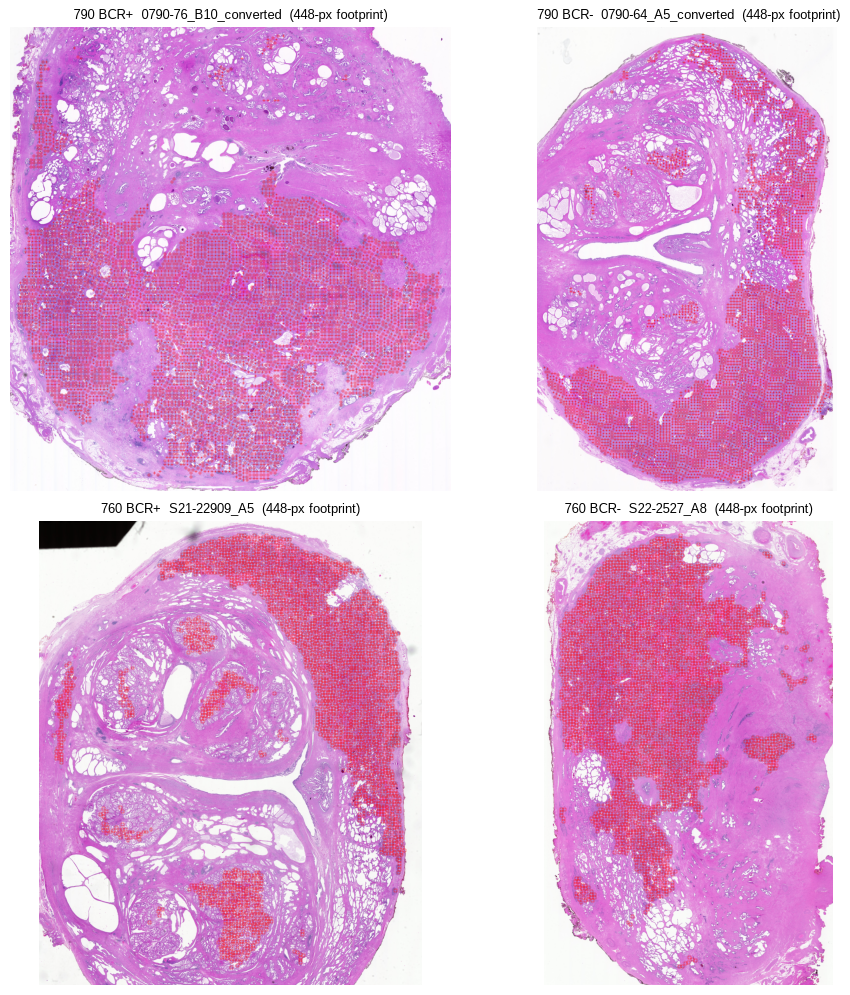


TIFF = {'790 BCR+': '/N/project/prostate_cancer_ai/Histopathology_Dataset/huron_converted_and_results/converted_huron_slides/0790-76 B10_converted.svs', '790 BCR-': '/N/project/prostate_cancer_ai/Histopathology_Dataset/huron_converted_and_results/converted_huron_slides/0790-64 A5_converted.svs', '760 BCR+': '/N/project/prostate_cancer_ai/Histopathology_Dataset/IUSM_Prostate_760/S21-22909_A5.tif', '760 BCR-': '/N/project/prostate_cancer_ai/Histopathology_Dataset/IUSM_Prostate_760/S22-2527_A8.tif'}


In [34]:
# ==== CELL 11: pick WSIs per cohort + check patch paths + match .tiff + confirm patch footprint ====
import glob                       # re-import: cells 8b/9 reused the name 'glob' for a variable
from openslide import OpenSlide
from scipy.spatial import cKDTree
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle
from PIL import Image

TIFF_DIRS = {   # searched recursively; for 790 the FIRST folder with a match wins
    '760': ['/N/project/prostate_cancer_ai/Histopathology_Dataset/IUSM_Prostate_760'],
    '790': ['/N/project/prostate_cancer_ai/Histopathology_Dataset/huron_converted_and_results/converted_huron_slides',
            '/N/project/prostate_cancer_ai/Histopathology_Dataset/IUSM_790_Huron_Yamlak_2',
            '/N/project/prostate_cancer_ai/Histopathology_Dataset/IUSM_790_Huron_Yamlak'],
}
PATH_REMAP = None          # e.g. ('/old/prefix/', '/new/prefix/') only if patch PNGs moved
PICK_OVERRIDE = {}         # e.g. {'790': {'BCR+': '0790-xx_..', 'BCR-': '...'}} to choose slides yourself

z = np.load(f'{OUT_DIR}/oof_patch_scores.npz', allow_pickle=False)
px, py = z['px'], z['py']
df_slides = pd.read_csv(f'{OUT_DIR}/oof_slides.csv')
PATCH_PATHS = np.array([str(p).replace(*PATH_REMAP) if PATH_REMAP else str(p) for p in z['paths']])
chk = np.random.default_rng(0).choice(len(PATCH_PATHS), 200, replace=False)
print('=== CELL 11 === patch paths existing (200 random):', sum(os.path.exists(PATCH_PATHS[i]) for i in chk), '/ 200')
if os.path.exists(PATCH_PATHS[0]): print('patch PNG size:', Image.open(PATCH_PATHS[0]).size)
np.save(f'{OUT_DIR}/patch_paths_remapped.npy', PATCH_PATHS)

# ---- candidates and picks: largest BCR+ / BCR- slide within each cohort ----
PICK = {}
for c in ['790', '760']:
    PICK[c] = {}
    for b_, nm in [(1, 'BCR+'), (0, 'BCR-')]:
        top3 = df_slides[(df_slides.cohort.astype(str) == c) & (df_slides.bcr == b_)].nlargest(3, 'n_patches')
        print(f'\n[{c} {nm}] largest:', ', '.join(f'{r.slide} ({r.n_patches})' for _, r in top3.iterrows()))
        PICK[c][nm] = PICK_OVERRIDE.get(c, {}).get(nm, top3.slide.iloc[0])
print('\nPICK =', PICK)

# ---- index slide files per folder (priority order kept) ----
def norm_name(p):
    b_ = os.path.basename(p)
    for ext in ['.ome.tiff', '.ome.tif', '.tiff', '.tif', '.svs', '.ndpi', '.mrxs']:
        if b_.lower().endswith(ext): b_ = b_[:-len(ext)]; break
    return b_.replace(' ', '_').lower()
INDEX = {}
for c, dirs in TIFF_DIRS.items():
    INDEX[c] = []
    for d_ in dirs:
        files = [p for p in glob.glob(f'{d_}/**/*', recursive=True)
                 if p.lower().endswith(('.tif', '.tiff', '.svs', '.ndpi', '.mrxs'))]
        idx = {}
        for p in files: idx.setdefault(norm_name(p), []).append(p)
        INDEX[c].append((d_, idx))
        print(f'[{c}] {len(files):5d} slide files in {d_}')

def find_tiff(key, c):
    keys = {key.lower(), key.lower().replace('_converted', '')}
    for d_, idx in INDEX[c]:
        hits = [p for k in keys for p in idx.get(k, [])]
        if hits: return sorted(set(hits)), d_
    return [], None

TIFF = {}
fig, axes = plt.subplots(2, 2, figsize=(10, 10)); axes = axes.ravel(); ai = 0
for c in ['790', '760']:
    for lab, key in PICK[c].items():
        ax = axes[ai]; ai += 1
        r = df_slides.set_index('slide').loc[key]; s, e = int(r.start), int(r.end); x, y_ = px[s:e], py[s:e]
        nn = cKDTree(np.c_[x, y_]).query(np.c_[x, y_], k=2)[0][:, 1]
        hits, d_ = find_tiff(key, c)
        print(f'\n[{c} {lab}] {key} | patches={e - s} | NN spacing median={np.median(nn):.0f} | x mod {PATCH} = {np.unique(x % PATCH)[:5]}')
        if not hits:
            stem = key.split('_')[0].lower()
            near = [os.path.basename(p) for _, idx in INDEX[c] for k_, ps in idx.items() if stem in k_ for p in ps][:6]
            print('   NO MATCH | files containing', repr(stem), ':', near); ax.axis('off'); continue
        if len(hits) > 1: print('   several matches in the same folder:', hits)
        TIFF[(c, lab)] = hits[0]
        sl = OpenSlide(hits[0]); W0, H0 = sl.level_dimensions[0]; pr = sl.properties
        print('   ->', hits[0], '| from folder:', d_)
        print('   level dims:', sl.level_dimensions[:4], '| downsamples:', [round(v, 2) for v in sl.level_downsamples[:4]])
        print('   mpp-x:', pr.get('openslide.mpp-x'), '| objective:', pr.get('openslide.objective-power'))
        print('   coords inside level 0?', x.max() + PATCH <= W0, y_.max() + PATCH <= H0)
        thumb = sl.get_thumbnail((2500, 2500)); sc = thumb.width / W0
        ax.imshow(thumb)
        ax.add_collection(PatchCollection([Rectangle((xi * sc, yi * sc), PATCH * sc, PATCH * sc) for xi, yi in zip(x, y_)],
                                          facecolor='none', edgecolor='red', lw=0.25))
        ax.set_xlim((x.min() - 2000) * sc, (x.max() + 3000) * sc); ax.set_ylim((y_.max() + 3000) * sc, (y_.min() - 2000) * sc)
        ax.set_title(f'{c} {lab}  {key}  ({PATCH}-px footprint)', fontsize=9); ax.axis('off')
        sl.close()
plt.tight_layout(); fig.savefig(f'{OUT_DIR}/geometry_check.png', dpi=150); plt.show()
print('\nTIFF =', {f'{k[0]} {k[1]}': v for k, v in TIFF.items()})

[790 BCR+ Glandular] coloured 86% of patches | winner shares: Gleason Pattern 5 16%, Gleason Pattern 4 1%, Single Luminal Cell Layer 48%, Comedonecrosis 28%, Prominent Nucleoli 7%
[790 BCR+ Stromal  ] coloured 100% of patches | winner shares: Neutrophils 33%, Myxoid Stroma 13%, Eosinophils 11%, Perineural Invasion 17%, Lymphocytic Infiltrate 26%
[790 BCR- Glandular] coloured 95% of patches | winner shares: Gleason Pattern 5 50%, Gleason Pattern 4 3%, Single Luminal Cell Layer 14%, Comedonecrosis 7%, Prominent Nucleoli 26%
[790 BCR- Stromal  ] coloured 100% of patches | winner shares: Neutrophils 31%, Myxoid Stroma 8%, Eosinophils 9%, Perineural Invasion 15%, Lymphocytic Infiltrate 37%


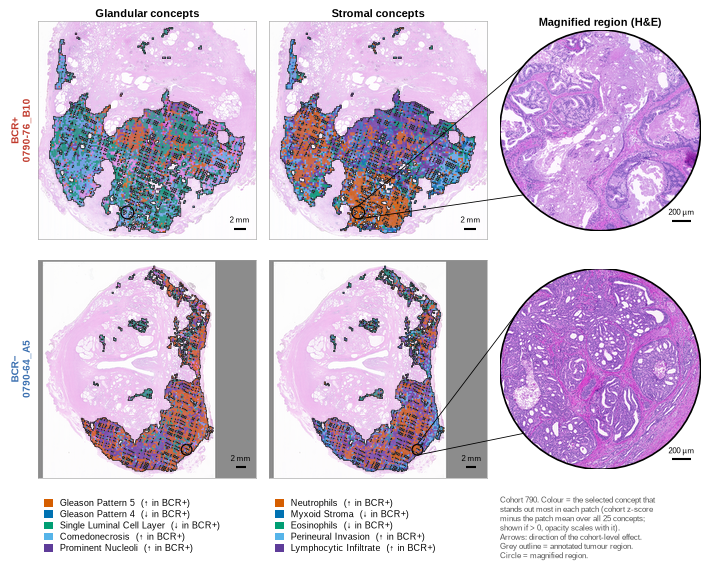

=== CELL 12 [790] === saved /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/fig_WSI_concept_maps_790.png/.pdf/.svg

[760 BCR+ Glandular] coloured 93% of patches | winner shares: Gleason Pattern 5 16%, Gleason Pattern 4 1%, Single Luminal Cell Layer 32%, Comedonecrosis 43%, Prominent Nucleoli 8%
[760 BCR+ Stromal  ] coloured 100% of patches | winner shares: Neutrophils 47%, Myxoid Stroma 10%, Eosinophils 11%, Perineural Invasion 19%, Lymphocytic Infiltrate 12%
[760 BCR- Glandular] coloured 96% of patches | winner shares: Gleason Pattern 5 43%, Gleason Pattern 4 1%, Single Luminal Cell Layer 22%, Comedonecrosis 29%, Prominent Nucleoli 6%
[760 BCR- Stromal  ] coloured 100% of patches | winner shares: Neutrophils 18%, Myxoid Stroma 5%, Eosinophils 3%, Perineural Invasion 18%, Lymphocytic Infiltrate 55%


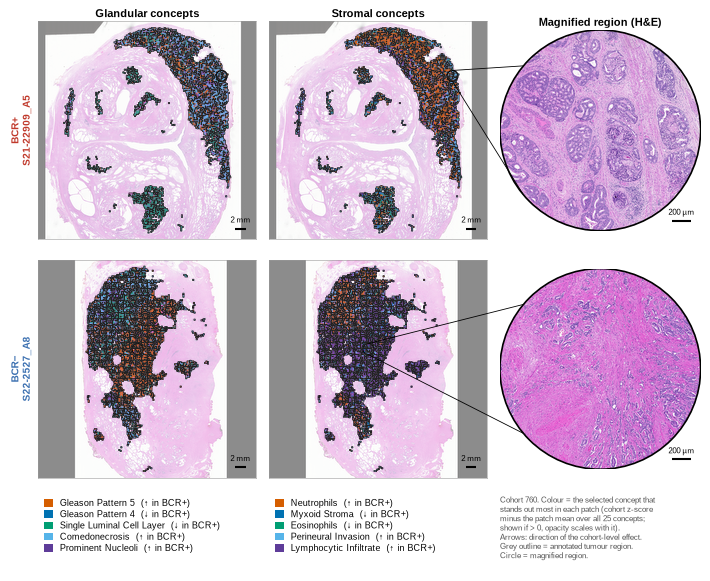

=== CELL 12 [760] === saved /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/fig_WSI_concept_maps_760.png/.pdf/.svg

ROI centres (level-0 px): {'790 BCR+': (51648, 132288), '790 BCR-': (95936, 125568), '760 BCR+': (57920, 18720), '760 BCR-': (20064, 34752)}
single panels in /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/panels


In [35]:
# ==== CELL 12: WSI concept maps (glandular | stromal | magnifier), one figure per cohort ====
from matplotlib.patches import Circle, ConnectionPatch, Patch as LegPatch
from matplotlib.gridspec import GridSpec

PATCH_OF    = {'790': 896, '760': 448}     # level-0 footprint per cohort (cell 11)
ROI_PATCHES = 8                            # magnifier diameter, in patches
Z_FLOOR     = 0.0                          # colour a patch only if its best selected concept stands out (>0)
MAP_PX, INSET_PX = 1600, 1200
CAT = ['#D55E00', '#0072B2', '#009E73', '#56B4E9', '#5E3C99']   # colour-blind-safe, rank 1..5
mpl.rcParams.update({'font.family': FONT, 'font.size': 7, 'svg.fonttype': 'none', 'pdf.fonttype': 42})
PANEL_DIR = f'{OUT_DIR}/panels'; os.makedirs(PANEL_DIR, exist_ok=True)

# ---- patch-level relative concept score (same logic as the slide-level primary analysis) ----
coh_patch = np.empty(len(X_raw), dtype='<U3')
for _, r in df_slides.iterrows():
    coh_patch[int(r.start):int(r.end)] = str(r.cohort)
Zp = np.empty_like(X_raw)
for c in COHORTS:
    k = coh_patch == c
    Zp[k] = (X_raw[k] - X_raw[k].mean(0)) / (X_raw[k].std(0) + 1e-9)
REL = (Zp - Zp.mean(1, keepdims=True)).astype(np.float32)
np.save(f'{OUT_DIR}/patch_concept_relz.npy', REL)

SEL = {g_: [int(c) for c in v] for g_, v in json.load(open(f'{OUT_DIR}/selected_concepts.json')).items()}
rel_stats = pd.read_csv(f'{OUT_DIR}/averaged_cam_stats_raw_all_relative.csv').set_index('col')
SL = df_slides.set_index('slide')
name  = lambda c: str(SHORT[c])
arrow = lambda c: '↑' if rel_stats.loc[c, 'delta'] > 0 else '↓'
short_key = lambda k: k.replace('_converted', '')

def winners(s, e, cols):
    zz = REL[s:e][:, cols]; return zz.argmax(1), zz.max(1)

def pick_roi(s, e, P0):
    cx, cy = px[s:e] + P0 / 2, py[s:e] + P0 / 2
    strength = np.clip(winners(s, e, SEL['Glandular'])[1], 0, None) + np.clip(winners(s, e, SEL['Stromal'])[1], 0, None)
    R = ROI_PATCHES * P0 / 2; full = np.pi * (R / P0) ** 2
    best, bi = -np.inf, 0
    for i, nb in enumerate(cKDTree(np.c_[cx, cy]).query_ball_point(np.c_[cx, cy], R)):
        if len(nb) / full >= 0.7 and strength[nb].mean() > best:
            best, bi = strength[nb].mean(), i
    return cx[bi], cy[bi], R

def read_square(sl, x0, y0, side, out_px):
    lvl = sl.get_best_level_for_downsample(side / out_px); dsf = sl.level_downsamples[lvl]
    im = sl.read_region((int(x0), int(y0)), lvl, (int(side / dsf), int(side / dsf))).convert('RGB')
    return np.asarray(im.resize((out_px, out_px), Image.LANCZOS)) / 255.0

def render_map(base, x0, sc, xs, ys, win, strength, P0):
    H_ = base.shape[0]; P = max(1, int(round(P0 * sc)))
    mask = np.zeros((H_, H_), bool); col = np.zeros((H_, H_, 3)); alpha = np.zeros((H_, H_, 1))
    for xi, yi, w_, st in zip(xs, ys, win, strength):
        c0, r0 = int((xi - x0[0]) * sc), int((yi - x0[1]) * sc)
        mask[r0:r0 + P, c0:c0 + P] = True
        if st > Z_FLOOR:
            col[r0:r0 + P, c0:c0 + P] = mpl.colors.to_rgb(CAT[w_])
            alpha[r0:r0 + P, c0:c0 + P] = np.clip(0.5 + 0.15 * st, 0.5, 0.88)
    faded = np.where(mask[..., None], base, 0.45 * base + 0.55)
    return faded * (1 - alpha) + col * alpha, mask

def scalebar(ax, length_px, label, H_, color='k'):
    x1 = H_ * 0.95; ax.plot([x1 - length_px, x1], [H_ * 0.95] * 2, color=color, lw=1.5, solid_capstyle='butt')
    ax.text(x1 - length_px / 2, H_ * 0.93, label, ha='center', va='bottom', fontsize=6, color=color)

ROI, GEOM = {}, {}
for coh_ in ['790', '760']:
    P0 = PATCH_OF[coh_]
    fig = plt.figure(figsize=(7.2, 5.9))
    gs = GridSpec(3, 3, figure=fig, height_ratios=[1, 1, 0.34], width_ratios=[1, 1, 0.92],
                  left=0.07, right=0.99, top=0.95, bottom=0.01, wspace=0.06, hspace=0.06)
    for row, (lab, key) in enumerate(PICK[coh_].items()):
        r = SL.loc[key]; s, e = int(r.start), int(r.end)
        sl = OpenSlide(TIFF[(coh_, lab)]); mpp = float(sl.properties.get('openslide.mpp-x', 0.5) or 0.5)
        xs, ys = px[s:e], py[s:e]
        side = max(xs.max() + P0 - xs.min(), ys.max() + P0 - ys.min()) * 1.06
        x0 = ((xs.min() + xs.max() + P0) / 2 - side / 2, (ys.min() + ys.max() + P0) / 2 - side / 2)
        base = read_square(sl, *x0, side, MAP_PX); sc = MAP_PX / side
        GEOM[(coh_, lab)] = dict(x0=x0, side=side, mpp=mpp)
        cx, cy, R = pick_roi(s, e, P0); ROI[(coh_, lab)] = (cx, cy, R)
        for colx, g_ in enumerate(['Glandular', 'Stromal']):
            win, st = winners(s, e, SEL[g_])
            img, mask = render_map(base, x0, sc, xs, ys, win, st, P0)
            ax = fig.add_subplot(gs[row, colx]); ax.imshow(img, interpolation='lanczos')
            ax.contour(mask.astype(float), levels=[0.5], colors='#222222', linewidths=0.5)
            ax.add_patch(Circle(((cx - x0[0]) * sc, (cy - x0[1]) * sc), R * sc, fill=False, ec='k', lw=0.9))
            scalebar(ax, 2000 / mpp * sc, '2 mm', MAP_PX); ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values(): sp.set_linewidth(0.4); sp.set_color('#999999')
            if row == 0: ax.set_title(f'{g_} concepts', fontsize=8, fontweight='bold', pad=3)
            if colx == 0:
                ax.set_ylabel(f"{lab.replace('-', chr(8722))}\n{short_key(key)}", fontsize=7.5, fontweight='bold',
                              color='#C0392B' if lab == 'BCR+' else '#3A6FB0')
            plt.imsave(f'{PANEL_DIR}/map_{coh_}_{lab}_{g_}.png', np.clip(img, 0, 1))
            if colx == 1: ax_map = ax
            shares = np.bincount(win[st > Z_FLOOR], minlength=len(SEL[g_])) / max(1, (st > Z_FLOOR).sum())
            print(f'[{coh_} {lab} {g_:9s}] coloured {np.mean(st > Z_FLOOR):.0%} of patches | winner shares: ' +
                  ', '.join(f'{name(c)} {sh:.0%}' for c, sh in zip(SEL[g_], shares)))
        roi = read_square(sl, cx - R, cy - R, 2 * R, INSET_PX); sl.close()
        axi = fig.add_subplot(gs[row, 2]); im = axi.imshow(roi, interpolation='lanczos')
        im.set_clip_path(Circle((0.5, 0.5), 0.5, transform=axi.transAxes))
        axi.add_patch(Circle((0.5, 0.5), 0.5, transform=axi.transAxes, fill=False, ec='k', lw=1.2))
        scalebar(axi, 200 / mpp * INSET_PX / (2 * R), '200 µm', INSET_PX)
        axi.axis('off'); plt.imsave(f'{PANEL_DIR}/magnifier_{coh_}_{lab}.png', roi)
        if row == 0: axi.set_title('Magnified region (H&E)', fontsize=8, fontweight='bold', pad=3)
        for ya, ang in [(-1, 140), (1, 220)]:
            fig.add_artist(ConnectionPatch(xyA=((cx - x0[0]) * sc, (cy - x0[1] + ya * R) * sc), coordsA=ax_map.transData,
                                           xyB=(0.5 + 0.5 * np.cos(np.radians(ang)), 0.5 + 0.5 * np.sin(np.radians(ang))),
                                           coordsB=axi.transAxes, color='k', lw=0.6))
    for colx, g_ in enumerate(['Glandular', 'Stromal']):
        axl = fig.add_subplot(gs[2, colx]); axl.axis('off')
        axl.legend(handles=[LegPatch(fc=CAT[k], ec='none', label=f'{name(c)}  ({arrow(c)} in BCR+)') for k, c in enumerate(SEL[g_])],
                   loc='upper left', ncol=1, frameon=False, fontsize=6.5, handlelength=1.0, handleheight=0.9,
                   borderaxespad=0.2, labelspacing=0.25)
    axn = fig.add_subplot(gs[2, 2]); axn.axis('off')
    axn.text(0, 0.97, f'Cohort {coh_}. Colour = the selected concept that\nstands out most in each patch (cohort z-score\n'
             'minus the patch mean over all 25 concepts;\nshown if > 0, opacity scales with it).\n'
             'Arrows: direction of the cohort-level effect.\nGrey outline = annotated tumour region.\nCircle = magnified region.',
             va='top', fontsize=6.0, color='#555555')
    stem = f'{OUT_DIR}/fig_WSI_concept_maps_{coh_}'
    for ext in ['png', 'pdf', 'svg']:
        fig.savefig(f'{stem}.{ext}', dpi=600, facecolor='white')
    plt.show()
    print(f'=== CELL 12 [{coh_}] === saved {stem}.png/.pdf/.svg\n')

print('ROI centres (level-0 px):', {f'{k[0]} {k[1]}': (int(v[0]), int(v[1])) for k, v in ROI.items()})
print('single panels in', PANEL_DIR)

In [36]:
# ==== CELL 12a: choose representative example slides (out-of-fold mean-concept probe) ====
pred = pickle.load(open(f'{MODEL_ROOT}/results/protocolB_predictions.pkl', 'rb'))
p_oof = pd.Series(np.asarray(pred['preds']['base_concept_mean'], dtype=float).reshape(-1),
                  index=[str(s_) for s_ in pred['slides']])
y_chk = pd.Series(np.asarray(pred['y']).astype(int), index=p_oof.index)
print('=== CELL 12a === OOF probe AUC (should be 0.731):', round(roc_auc_score(y_chk, p_oof), 3))

# relative slide profile (rebuilt; name REL_SLIDE so later cells cannot overwrite it)
Zs_ = cohort_z(SLIDE_CAM['raw_all'], coh); REL_SLIDE = Zs_ - Zs_.mean(1, keepdims=True)
sig = REL_SLIDE @ rel.sort_values('col').delta.values

df_pick = df_slides[['slide', 'cohort', 'bcr', 'n_patches']].copy()
df_pick['cohort'] = df_pick.cohort.astype(str)
df_pick['p_oof'] = df_pick.slide.map(p_oof); df_pick['signature'] = sig
assert df_pick.p_oof.notna().all() and (df_pick.slide.map(y_chk) == df_pick.bcr).all(), 'slide/label mismatch with predictions file'

PICK = {}
for c in ['790', '760']:
    sub = df_pick[(df_pick.cohort == c) & (df_pick.n_patches >= df_pick[df_pick.cohort == c].n_patches.median())]
    pos, neg = sub[sub.bcr == 1].sort_values('p_oof', ascending=False), sub[sub.bcr == 0].sort_values('p_oof')
    print(f'\n[{c}] slides >= median size ({int(df_pick[df_pick.cohort == c].n_patches.median())} patches): {len(sub)}')
    print('  BCR+ highest OOF prob:', ', '.join(f'{r.slide} (p={r.p_oof:.2f}, sig={r.signature:+.1f}, n={r.n_patches})' for _, r in pos.head(3).iterrows()))
    print('  BCR- lowest  OOF prob:', ', '.join(f'{r.slide} (p={r.p_oof:.2f}, sig={r.signature:+.1f}, n={r.n_patches})' for _, r in neg.head(3).iterrows()))
    PICK[c] = {'BCR+': pos.slide.iloc[0], 'BCR-': neg.slide.iloc[0]}
    for lab, k in PICK[c].items():
        hits, d_ = find_tiff(k, c)
        print(f'  -> {lab}: {k} | slide file: {hits[0] if hits else "NOT FOUND"}')
        if hits: TIFF[(c, lab)] = hits[0]
print('\nPICK =', PICK)
df_pick.to_csv(f'{OUT_DIR}/example_slide_candidates.csv', index=False)

=== CELL 12a === OOF probe AUC (should be 0.731): 0.731

[790] slides >= median size (963 patches): 41
  BCR+ highest OOF prob: 0790-12_A4_converted (p=0.83, sig=+2.6, n=2324), 0790-18_A4_converted (p=0.74, sig=+0.9, n=3966), 0790-76_B10_converted (p=0.64, sig=+0.9, n=5859)
  BCR- lowest  OOF prob: 0790-66_A8_converted (p=0.02, sig=-5.5, n=2126), 0790-80_E4_converted (p=0.06, sig=+0.9, n=1026), 0790-58_F7_converted (p=0.08, sig=-2.9, n=2010)
  -> BCR+: 0790-12_A4_converted | slide file: /N/project/prostate_cancer_ai/Histopathology_Dataset/huron_converted_and_results/converted_huron_slides/0790-12 A4_converted.svs
  -> BCR-: 0790-66_A8_converted | slide file: /N/project/prostate_cancer_ai/Histopathology_Dataset/huron_converted_and_results/converted_huron_slides/0790-66 A8_converted.svs

[760] slides >= median size (1122 patches): 24
  BCR+ highest OOF prob: S21-22909_A5 (p=0.73, sig=+2.4, n=2957), S21-29905_A7 (p=0.63, sig=+6.8, n=1657), S22-6495_B4 (p=0.52, sig=+2.7, n=2451)
  BCR- low

[790 BCR+ Glandular] coloured 86% | winner shares: Gleason Pattern 5 16%, Gleason Pattern 4 3%, Single Luminal Cell Layer 26%, Comedonecrosis 50%, Prominent Nucleoli 5%
[790 BCR+ Stromal  ] coloured 80% | winner shares: Neutrophils 38%, Myxoid Stroma 8%, Eosinophils 12%, Perineural Invasion 35%, Lymphocytic Infiltrate 7%
[790 BCR- Glandular] coloured 60% | winner shares: Gleason Pattern 5 2%, Gleason Pattern 4 2%, Single Luminal Cell Layer 70%, Comedonecrosis 15%, Prominent Nucleoli 10%
[790 BCR- Stromal  ] coloured 91% | winner shares: Neutrophils 14%, Myxoid Stroma 25%, Eosinophils 51%, Perineural Invasion 5%, Lymphocytic Infiltrate 6%


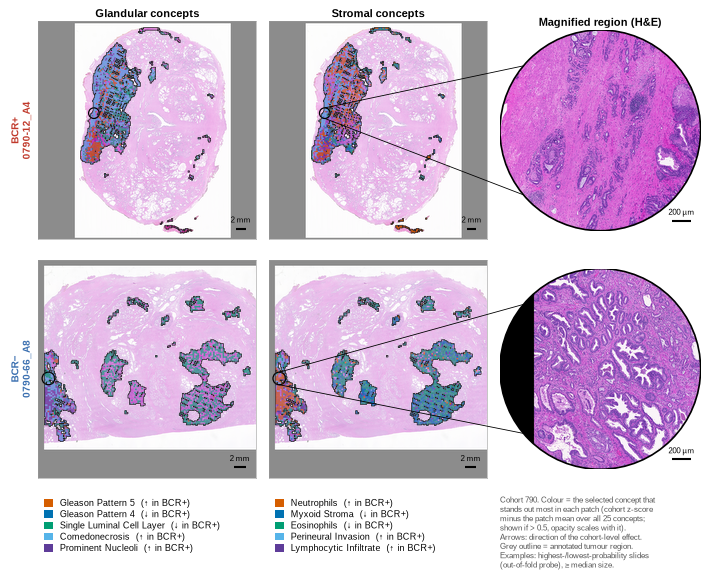

=== CELL 12 [790] === saved /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/fig_WSI_concept_maps_790.png/.pdf/.svg

[760 BCR+ Glandular] coloured 84% | winner shares: Gleason Pattern 5 17%, Gleason Pattern 4 0%, Single Luminal Cell Layer 30%, Comedonecrosis 44%, Prominent Nucleoli 8%
[760 BCR+ Stromal  ] coloured 95% | winner shares: Neutrophils 48%, Myxoid Stroma 10%, Eosinophils 11%, Perineural Invasion 19%, Lymphocytic Infiltrate 12%
[760 BCR- Glandular] coloured 70% | winner shares: Gleason Pattern 5 0%, Gleason Pattern 4 9%, Single Luminal Cell Layer 83%, Comedonecrosis 5%, Prominent Nucleoli 2%
[760 BCR- Stromal  ] coloured 76% | winner shares: Neutrophils 2%, Myxoid Stroma 53%, Eosinophils 18%, Perineural Invasion 2%, Lymphocytic Infiltrate 24%


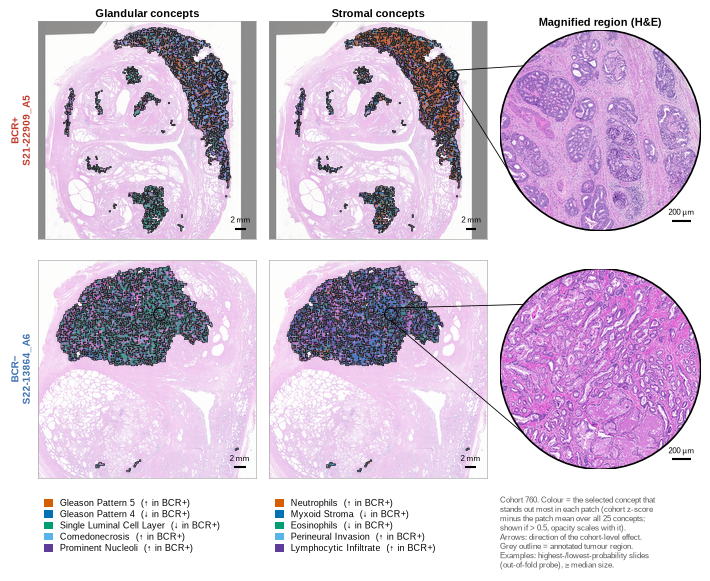

=== CELL 12 [760] === saved /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/fig_WSI_concept_maps_760.png/.pdf/.svg

ROI centres (level-0 px): {'790 BCR+': (12800, 60608), '790 BCR-': (2368, 64000), '760 BCR+': (57920, 18720), '760 BCR-': (37312, 18912)}


In [37]:
# ==== CELL 12 (v2): WSI concept maps (glandular | stromal | magnifier), one figure per cohort ====
from matplotlib.patches import Circle, ConnectionPatch, Patch as LegPatch
from matplotlib.gridspec import GridSpec

PATCH_OF    = {'790': 896, '760': 448}     # level-0 footprint per cohort (cell 11)
ROI_PATCHES = 8                            # magnifier diameter, in patches
Z_FLOOR     = 0.5                          # colour a patch only if a selected concept clearly stands out
MAP_PX, INSET_PX = 1600, 1200
CAT = ['#D55E00', '#0072B2', '#009E73', '#56B4E9', '#5E3C99']   # colour-blind-safe, rank 1..5
mpl.rcParams.update({'font.family': FONT, 'font.size': 7, 'svg.fonttype': 'none', 'pdf.fonttype': 42})
PANEL_DIR = f'{OUT_DIR}/panels'; os.makedirs(PANEL_DIR, exist_ok=True)

# ---- patch-level relative concept score (same logic as the slide-level primary analysis) ----
coh_patch = np.empty(len(X_raw), dtype='<U3')
for _, r_ in df_slides.iterrows():
    coh_patch[int(r_.start):int(r_.end)] = str(r_.cohort)
Zp = np.empty_like(X_raw)
for c in COHORTS:
    k = coh_patch == c
    Zp[k] = (X_raw[k] - X_raw[k].mean(0)) / (X_raw[k].std(0) + 1e-9)
REL_PATCH = (Zp - Zp.mean(1, keepdims=True)).astype(np.float32)
np.save(f'{OUT_DIR}/patch_concept_relz.npy', REL_PATCH)

SEL = {g_: [int(c) for c in v] for g_, v in json.load(open(f'{OUT_DIR}/selected_concepts.json')).items()}
rel_stats = pd.read_csv(f'{OUT_DIR}/averaged_cam_stats_raw_all_relative.csv').set_index('col')
SL = df_slides.set_index('slide')
name  = lambda c: str(SHORT[c])
arrow = lambda c: '↑' if rel_stats.loc[c, 'delta'] > 0 else '↓'
short_key = lambda k: k.replace('_converted', '')

def winners(s, e, cols):
    zz = REL_PATCH[s:e][:, cols]; return zz.argmax(1), zz.max(1)

def pick_roi(s, e, P0):
    cx, cy = px[s:e] + P0 / 2, py[s:e] + P0 / 2
    strength = np.clip(winners(s, e, SEL['Glandular'])[1], 0, None) + np.clip(winners(s, e, SEL['Stromal'])[1], 0, None)
    rad = ROI_PATCHES * P0 / 2; full = np.pi * (rad / P0) ** 2
    best, bi = -np.inf, 0
    for i, nb in enumerate(cKDTree(np.c_[cx, cy]).query_ball_point(np.c_[cx, cy], rad)):
        if len(nb) / full >= 0.7 and strength[nb].mean() > best:
            best, bi = strength[nb].mean(), i
    return cx[bi], cy[bi], rad

def read_square(sl, x0, y0, side, out_px):
    lvl = sl.get_best_level_for_downsample(side / out_px); dsf = sl.level_downsamples[lvl]
    im = sl.read_region((int(x0), int(y0)), lvl, (int(side / dsf), int(side / dsf))).convert('RGB')
    return np.asarray(im.resize((out_px, out_px), Image.LANCZOS)) / 255.0

def render_map(base, x0, sc, xs, ys, win, strength, P0):
    H_ = base.shape[0]; P = max(1, int(round(P0 * sc)))
    mask = np.zeros((H_, H_), bool); col = np.zeros((H_, H_, 3)); alpha = np.zeros((H_, H_, 1))
    for xi, yi, w_, st in zip(xs, ys, win, strength):
        c0, r0 = int((xi - x0[0]) * sc), int((yi - x0[1]) * sc)
        mask[r0:r0 + P, c0:c0 + P] = True
        if st > Z_FLOOR:
            col[r0:r0 + P, c0:c0 + P] = mpl.colors.to_rgb(CAT[w_])
            alpha[r0:r0 + P, c0:c0 + P] = np.clip(0.5 + 0.15 * (st - Z_FLOOR), 0.5, 0.88)
    faded = np.where(mask[..., None], base, 0.45 * base + 0.55)
    return faded * (1 - alpha) + col * alpha, mask

def scalebar(ax, length_px, label, H_, color='k'):
    x1 = H_ * 0.95; ax.plot([x1 - length_px, x1], [H_ * 0.95] * 2, color=color, lw=1.5, solid_capstyle='butt')
    ax.text(x1 - length_px / 2, H_ * 0.93, label, ha='center', va='bottom', fontsize=6, color=color)

ROI, GEOM = {}, {}
for coh_ in ['790', '760']:
    P0 = PATCH_OF[coh_]
    fig = plt.figure(figsize=(7.2, 5.9))
    gs = GridSpec(3, 3, figure=fig, height_ratios=[1, 1, 0.34], width_ratios=[1, 1, 0.92],
                  left=0.07, right=0.99, top=0.95, bottom=0.01, wspace=0.06, hspace=0.06)
    for row, (lab, key) in enumerate(PICK[coh_].items()):
        r_ = SL.loc[key]; s, e = int(r_.start), int(r_.end)
        sl = OpenSlide(TIFF[(coh_, lab)]); mpp = float(sl.properties.get('openslide.mpp-x', 0.5) or 0.5)
        xs, ys = px[s:e], py[s:e]
        side = max(xs.max() + P0 - xs.min(), ys.max() + P0 - ys.min()) * 1.06
        x0 = ((xs.min() + xs.max() + P0) / 2 - side / 2, (ys.min() + ys.max() + P0) / 2 - side / 2)
        base = read_square(sl, *x0, side, MAP_PX); sc = MAP_PX / side
        GEOM[(coh_, lab)] = dict(x0=x0, side=side, mpp=mpp, P0=P0)
        cx, cy, rad = pick_roi(s, e, P0); ROI[(coh_, lab)] = (cx, cy, rad)
        for colx, g_ in enumerate(['Glandular', 'Stromal']):
            win, st = winners(s, e, SEL[g_])
            img, mask = render_map(base, x0, sc, xs, ys, win, st, P0)
            ax = fig.add_subplot(gs[row, colx]); ax.imshow(img, interpolation='lanczos')
            ax.contour(mask.astype(float), levels=[0.5], colors='#222222', linewidths=0.5)
            ax.add_patch(Circle(((cx - x0[0]) * sc, (cy - x0[1]) * sc), rad * sc, fill=False, ec='k', lw=0.9))
            scalebar(ax, 2000 / mpp * sc, '2 mm', MAP_PX); ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values(): sp.set_linewidth(0.4); sp.set_color('#999999')
            if row == 0: ax.set_title(f'{g_} concepts', fontsize=8, fontweight='bold', pad=3)
            if colx == 0:
                ax.set_ylabel(f"{lab.replace('-', chr(8722))}\n{short_key(key)}", fontsize=7.5, fontweight='bold',
                              color='#C0392B' if lab == 'BCR+' else '#3A6FB0')
            plt.imsave(f'{PANEL_DIR}/map_{coh_}_{lab}_{g_}.png', np.clip(img, 0, 1))
            if colx == 1: ax_map = ax
            on = st > Z_FLOOR
            shares = np.bincount(win[on], minlength=len(SEL[g_])) / max(1, on.sum())
            print(f'[{coh_} {lab} {g_:9s}] coloured {on.mean():.0%} | winner shares: ' +
                  ', '.join(f'{name(c)} {sh:.0%}' for c, sh in zip(SEL[g_], shares)))
        roi_img = read_square(sl, cx - rad, cy - rad, 2 * rad, INSET_PX); sl.close()
        axi = fig.add_subplot(gs[row, 2]); im = axi.imshow(roi_img, interpolation='lanczos')
        im.set_clip_path(Circle((0.5, 0.5), 0.5, transform=axi.transAxes))
        axi.add_patch(Circle((0.5, 0.5), 0.5, transform=axi.transAxes, fill=False, ec='k', lw=1.2))
        scalebar(axi, 200 / mpp * INSET_PX / (2 * rad), '200 µm', INSET_PX)
        axi.axis('off'); plt.imsave(f'{PANEL_DIR}/magnifier_{coh_}_{lab}.png', roi_img)
        if row == 0: axi.set_title('Magnified region (H&E)', fontsize=8, fontweight='bold', pad=3)
        for ya, ang in [(-1, 140), (1, 220)]:
            fig.add_artist(ConnectionPatch(xyA=((cx - x0[0]) * sc, (cy - x0[1] + ya * rad) * sc), coordsA=ax_map.transData,
                                           xyB=(0.5 + 0.5 * np.cos(np.radians(ang)), 0.5 + 0.5 * np.sin(np.radians(ang))),
                                           coordsB=axi.transAxes, color='k', lw=0.6))
    for colx, g_ in enumerate(['Glandular', 'Stromal']):
        axl = fig.add_subplot(gs[2, colx]); axl.axis('off')
        axl.legend(handles=[LegPatch(fc=CAT[k], ec='none', label=f'{name(c)}  ({arrow(c)} in BCR+)') for k, c in enumerate(SEL[g_])],
                   loc='upper left', ncol=1, frameon=False, fontsize=6.5, handlelength=1.0, handleheight=0.9,
                   borderaxespad=0.2, labelspacing=0.25)
    axn = fig.add_subplot(gs[2, 2]); axn.axis('off')
    axn.text(0, 0.97, f'Cohort {coh_}. Colour = the selected concept that\nstands out most in each patch (cohort z-score\n'
             f'minus the patch mean over all 25 concepts;\nshown if > {Z_FLOOR}, opacity scales with it).\n'
             'Arrows: direction of the cohort-level effect.\nGrey outline = annotated tumour region.\n'
             'Examples: highest-/lowest-probability slides\n(out-of-fold probe), ≥ median size.',
             va='top', fontsize=6.0, color='#555555')
    stem = f'{OUT_DIR}/fig_WSI_concept_maps_{coh_}'
    for ext in ['png', 'pdf', 'svg']:
        fig.savefig(f'{stem}.{ext}', dpi=600, facecolor='white')
    plt.show()
    print(f'=== CELL 12 [{coh_}] === saved {stem}.png/.pdf/.svg\n')

print('ROI centres (level-0 px):', {f'{k[0]} {k[1]}': (int(v[0]), int(v[1])) for k, v in ROI.items()})

fold 0: C = 0.316 | train 85 / test 43
fold 1: C = 0.01 | train 85 / test 43
fold 2: C = 0.316 | train 86 / test 42
=== CELL 12b === reconstructed OOF AUC = 0.731 (eval_probe: 0.731) | Spearman with eval_probe OOF probs = 1.000
attention vs BCR contribution, Spearman over all patches: 0.017
[790 BCR+] 0790-12_A4_converted: slide logit +1.60 | patches pushing toward BCR 68% | Spearman(attention, contribution) +0.47
     concepts raising risk : Myxoid Stroma +1.07, Increased Vascularity +0.84, Eosinophils +0.59
     concepts lowering risk: Mature Collagen -0.74, Collagenous Micronodules -0.36, Gleason Pattern 3 -0.21
[790 BCR-] 0790-66_A8_converted: slide logit -3.83 | patches pushing toward BCR 20% | Spearman(attention, contribution) -0.18
     concepts raising risk : Reactive Stroma +0.32, Collagenous Micronodules +0.30, Stromogenic Cancer +0.26
     concepts lowering risk: Eosinophils -1.01, Gleason Pattern 5 -0.90, Increased Vascularity -0.71


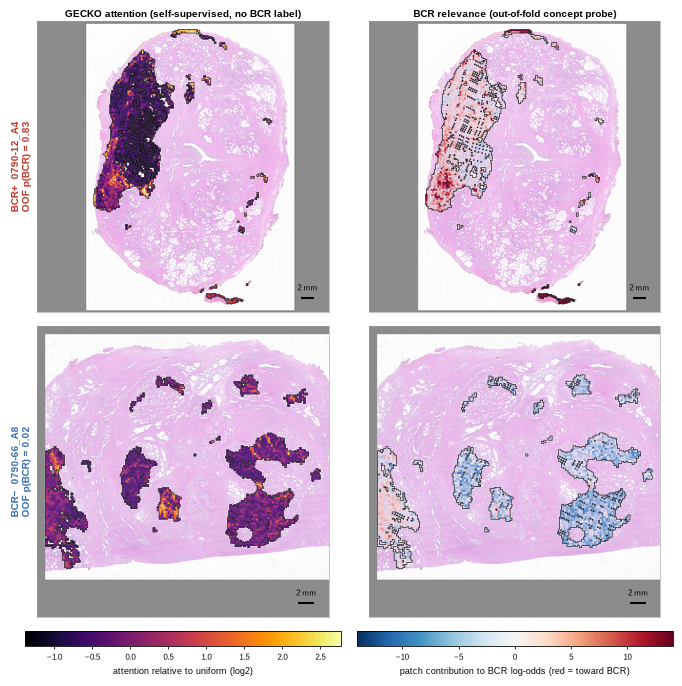

=== saved /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/fig_WSI_attention_relevance_790.png/.pdf/.svg

[760 BCR+] S21-22909_A5: slide logit +0.98 | patches pushing toward BCR 66% | Spearman(attention, contribution) -0.20
     concepts raising risk : Neutrophils +0.55, Myxoid Stroma +0.42, Gleason Pattern 5 +0.37
     concepts lowering risk: Complex Papillary Architecture -0.23, Single Luminal Cell Layer -0.20, Prominent Nucleoli -0.10
[760 BCR-] S22-13864_A6: slide logit -6.01 | patches pushing toward BCR 2% | Spearman(attention, contribution) -0.30
     concepts raising risk : Nuclear Atypia +0.32, Collagenous Micronodules +0.25, Mature Collagen +0.24
     concepts lowering risk: Gleason Pattern 5 -0.82, Myxoid Stroma -0.79, Neutrophils -0.79


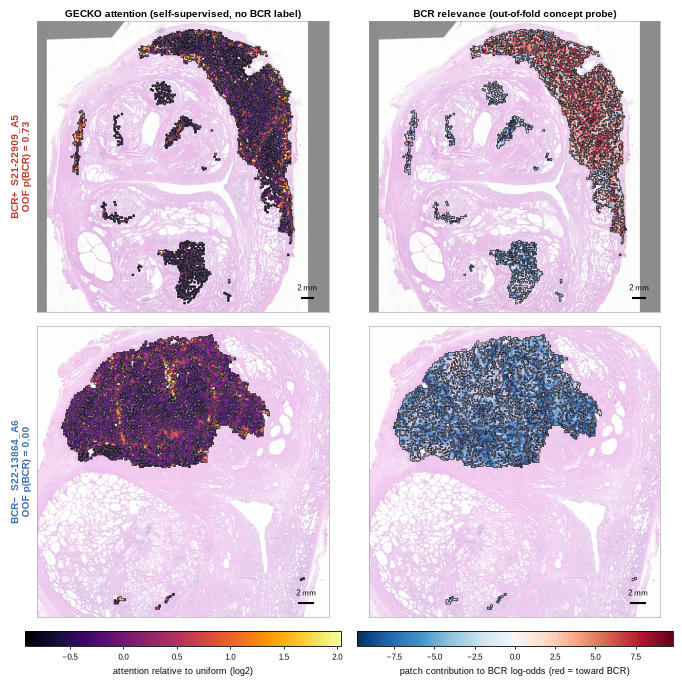

=== saved /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/fig_WSI_attention_relevance_760.png/.pdf/.svg



In [38]:
# ==== CELL 12b: GECKO attention (self-supervised) + BCR relevance (exact patch contributions of the concept probe) ====
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import RepeatedStratifiedKFold
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable

# ---- refit the mean-concept probe per Protocol B fold (eval_probe settings, no cohort norm) ----
Xs = SLIDE_CAM['raw_all']                       # per-slide mean raw concept scores (df_slides order)
contrib = np.full(len(X_raw), np.nan, np.float32); logit_oof = np.full(len(df_slides), np.nan); COEF = {}
for f in FOLDS:
    te = (df_slides.fold == f).values; tr = ~te
    scl = StandardScaler().fit(Xs[tr])
    lr = LogisticRegressionCV(Cs=np.logspace(-5, 3, 17), cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0),
                              scoring='roc_auc', class_weight='balanced', max_iter=10000, n_jobs=2).fit(scl.transform(Xs[tr]), y[tr])
    w, b0 = lr.coef_[0], lr.intercept_[0]
    COEF[f] = dict(w=w, b=b0, C=float(lr.C_[0]), mean=scl.mean_, scale=scl.scale_)
    for i in np.where(te)[0]:
        s, e = int(df_slides.start[i]), int(df_slides.end[i])
        cp_ = ((X_raw[s:e] - scl.mean_) / scl.scale_) @ w          # exact: slide logit = mean(cp_) + b
        contrib[s:e] = cp_; logit_oof[i] = cp_.mean() + b0
    print(f'fold {f}: C = {lr.C_[0]:.3g} | train {tr.sum()} / test {te.sum()}')
assert not np.isnan(contrib).any()
np.save(f'{OUT_DIR}/patch_bcr_contribution.npy', contrib)
p_ref = df_slides.slide.map(p_oof).values
print('=== CELL 12b === reconstructed OOF AUC = %.3f (eval_probe: 0.731) | Spearman with eval_probe OOF probs = %.3f'
      % (roc_auc_score(y, logit_oof), stats.spearmanr(logit_oof, p_ref).correlation))
print('attention vs BCR contribution, Spearman over all patches: %.3f' % stats.spearmanr(att, contrib).correlation)

def render_vals(base, x0, sc, xs, ys, rgb, P0, alpha=0.78):
    H_ = base.shape[0]; P = max(1, int(round(P0 * sc))); out = base.copy(); mask = np.zeros((H_, H_), bool)
    for xi, yi, cc in zip(xs, ys, rgb):
        c0, r0 = int((xi - x0[0]) * sc), int((yi - x0[1]) * sc); mask[r0:r0 + P, c0:c0 + P] = True
        out[r0:r0 + P, c0:c0 + P] = (1 - alpha) * out[r0:r0 + P, c0:c0 + P] + alpha * cc
    return np.where(mask[..., None], out, 0.45 * out + 0.55), mask

CM_ATT, CM_REL = plt.get_cmap('inferno'), plt.get_cmap('RdBu_r')
for coh_ in ['790', '760']:
    P0 = PATCH_OF[coh_]; rows = list(PICK[coh_].items())
    idx_all = np.concatenate([np.arange(int(SL.loc[k].start), int(SL.loc[k].end)) for _, k in rows])
    att_rel = {k: np.log2(att[int(SL.loc[k].start):int(SL.loc[k].end)] * SL.loc[k].n_patches) for _, k in rows}
    va = np.concatenate(list(att_rel.values()))
    n_att = Normalize(np.percentile(va, 2), np.percentile(va, 99.5))
    L = np.percentile(np.abs(contrib[idx_all]), 98); n_rel = TwoSlopeNorm(0, -L, L)
    fig = plt.figure(figsize=(7.2, 7.1))
    gs = GridSpec(3, 2, figure=fig, height_ratios=[1, 1, 0.05], left=0.09, right=0.99, top=0.95, bottom=0.07,
                  wspace=0.05, hspace=0.07)
    for row, (lab, key) in enumerate(rows):
        r_ = SL.loc[key]; s, e = int(r_.start), int(r_.end); i_sl = df_slides.index[df_slides.slide == key][0]
        gm = GEOM[(coh_, lab)]; sl = OpenSlide(TIFF[(coh_, lab)])
        base = read_square(sl, *gm['x0'], gm['side'], MAP_PX); sl.close(); sc = MAP_PX / gm['side']
        xs, ys = px[s:e], py[s:e]
        for colx, (vals, cmap_, nrm, ttl, tag) in enumerate([
                (att_rel[key], CM_ATT, n_att, 'GECKO attention (self-supervised, no BCR label)', 'attention'),
                (contrib[s:e], CM_REL, n_rel, 'BCR relevance (out-of-fold concept probe)', 'relevance')]):
            img, mask = render_vals(base, gm['x0'], sc, xs, ys, cmap_(nrm(vals))[:, :3], P0)
            ax = fig.add_subplot(gs[row, colx]); ax.imshow(np.clip(img, 0, 1), interpolation='lanczos')
            ax.contour(mask.astype(float), levels=[0.5], colors='#222222', linewidths=0.5)
            scalebar(ax, 2000 / gm['mpp'] * sc, '2 mm', MAP_PX); ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values(): sp.set_linewidth(0.4); sp.set_color('#999999')
            if row == 0: ax.set_title(ttl, fontsize=7.5, fontweight='bold', pad=3)
            if colx == 0:
                ax.set_ylabel(f"{lab.replace('-', chr(8722))}  {short_key(key)}\nOOF p(BCR) = {p_oof[key]:.2f}",
                              fontsize=7.2, fontweight='bold', color='#C0392B' if lab == 'BCR+' else '#3A6FB0')
            plt.imsave(f'{PANEL_DIR}/{tag}_{coh_}_{lab}.png', np.clip(img, 0, 1))
        cpn = contrib[s:e]; dr = COEF[int(r_.fold)]
        drv = dr['w'] * (Xs[i_sl] - dr['mean']) / dr['scale']; o = np.argsort(drv)
        print(f'[{coh_} {lab}] {key}: slide logit {logit_oof[i_sl]:+.2f} | patches pushing toward BCR {np.mean(cpn > 0):.0%} | '
              f'Spearman(attention, contribution) {stats.spearmanr(att[s:e], cpn).correlation:+.2f}')
        print('     concepts raising risk :', ', '.join(f'{SHORT[j]} {drv[j]:+.2f}' for j in o[::-1][:3]))
        print('     concepts lowering risk:', ', '.join(f'{SHORT[j]} {drv[j]:+.2f}' for j in o[:3]))
    for colx, (cmap_, nrm, lbl) in enumerate([(CM_ATT, n_att, 'attention relative to uniform (log2)'),
                                              (CM_REL, n_rel, 'patch contribution to BCR log-odds (red = toward BCR)')]):
        cax = fig.add_subplot(gs[2, colx])
        cb = fig.colorbar(ScalarMappable(norm=nrm, cmap=cmap_), cax=cax, orientation='horizontal')
        cb.set_label(lbl, fontsize=6.5); cb.ax.tick_params(labelsize=6, length=2)
    stem = f'{OUT_DIR}/fig_WSI_attention_relevance_{coh_}'
    for ext in ['png', 'pdf', 'svg']:
        fig.savefig(f'{stem}.{ext}', dpi=600, facecolor='white')
    plt.show(); print(f'=== saved {stem}.png/.pdf/.svg\n')

In [39]:
# ==== CELL 12c: probe weights vs cohort-level effects (sign check) ====
W = np.stack([COEF[f]['w'] for f in FOLDS])
wt = pd.DataFrame(dict(group=GROUP, concept=SHORT, w_mean=W.mean(0), w_min=W.min(0), w_max=W.max(0),
                       sign_stable=(np.sign(W) == np.sign(W.mean(0))).all(0),
                       g_abs=st_df.set_index('col').g.reindex(range(C)).values,
                       g_rel=rel.set_index('col').g.reindex(range(C)).values))
wt['w_agrees_with_g_abs'] = np.sign(wt.w_mean) == np.sign(wt.g_abs)
print('=== CELL 12c === probe weights (standardised mean concept scores), 3 folds')
print(wt.sort_values('w_mean').to_string(index=False, float_format=lambda v: f'{v:+.3f}'))
print('\nsign-stable across folds:', int(wt.sign_stable.sum()), '/ 25 | weight sign = univariate effect sign:',
      int(wt.w_agrees_with_g_abs.sum()), '/ 25')
for coh_ in ['790', '760']:
    for lab, key in PICK[coh_].items():
        i_sl = df_slides.index[df_slides.slide == key][0]; dr = COEF[int(df_slides.fold[i_sl])]
        zz = (Xs[i_sl] - dr['mean']) / dr['scale']; drv = dr['w'] * zz; o = np.argsort(-np.abs(drv))[:4]
        print(f'[{coh_} {lab}] ' + ' | '.join(f"{SHORT[j]}: {'high' if zz[j] > 0 else 'low'} (z {zz[j]:+.1f}), w {dr['w'][j]:+.2f} → {drv[j]:+.2f}" for j in o))
wt.to_csv(f'{OUT_DIR}/probe_weights_concept.csv', index=False)

=== CELL 12c === probe weights (standardised mean concept scores), 3 folds
    group                        concept  w_mean  w_min  w_max  sign_stable  g_abs  g_rel  w_agrees_with_g_abs
  Stromal                  Myxoid Stroma  -0.409 -0.731 -0.095         True -0.844 -0.610                 True
  Stromal                    Eosinophils  -0.392 -0.629 -0.057         True -0.731 -0.490                 True
Glandular          Amphophilic Cytoplasm  -0.390 -0.655 -0.085         True -0.505 -0.273                 True
Glandular              Cribriform Glands  -0.306 -0.651 -0.068         True -0.405 -0.153                 True
  Stromal          Increased Vascularity  -0.281 -0.452 -0.029         True -0.532 -0.269                 True
Glandular      Single Luminal Cell Layer  -0.255 -0.429 -0.080         True -0.710 -0.436                 True
  Stromal             Stromogenic Cancer  -0.206 -0.313 -0.058         True -0.188 +0.092                 True
Glandular Complex Papillary Architect

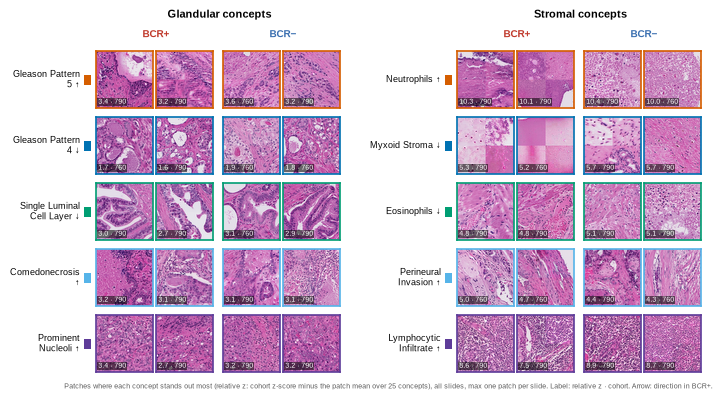

=== CELL 13 === panel C: 40 patches from 30 slides | saved /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/fig_patch_examples_cohort.png/.pdf/.svg
                                relz             cohorts         
side                            BCR+       BCR-     BCR+     BCR-
concept                                                          
Comedonecrosis              3.115456   3.090992  790/790  790/790
Eosinophils                 4.832795   5.079846  790/790  790/790
Gleason Pattern 4           1.677316   1.858145  760/790  760/760
Gleason Pattern 5           3.273779   3.396930  790/790  760/790
Lymphocytic Infiltrate      8.027573   8.795064  790/790  790/790
Myxoid Stroma               5.223308   5.694550  760/790  790/790
Neutrophils                10.164555  10.204973  790/790  760/790
Perineural Invasion         4.826401   4.322915  760/760  760/790
Prominent Nucleoli          3.047737   3.214770 

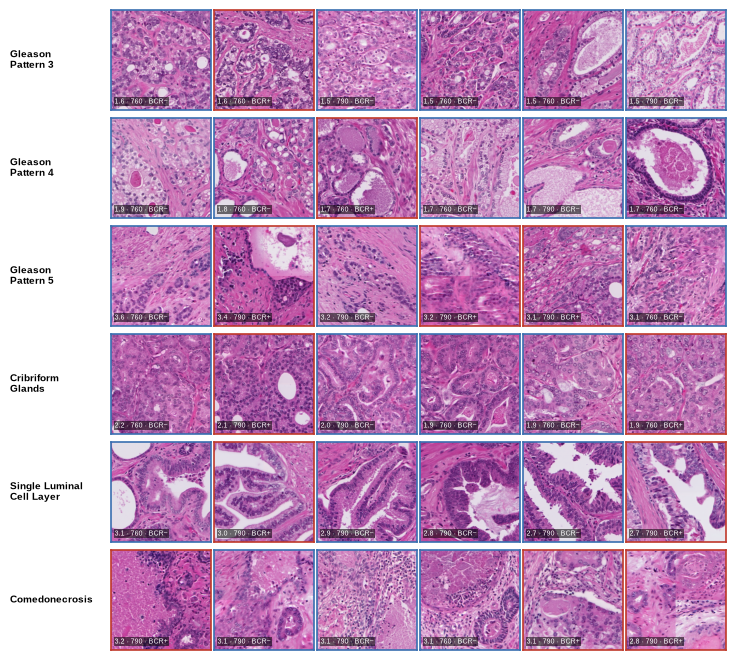

prompt sanity grid saved: /N/project/prostate_cancer_ai/Venkatesh/BCR_GECKO/BCR_prognosis_and_ISBI_exp/760_and_790_feature_dir/gecko_runs_v3/figures_cam/supp_prompt_sanity.png/.pdf (+ .csv with slide/patch per tile)


In [40]:
# ==== CELL 13: panel C (patch examples per selected concept, BCR+ vs BCR-) + prompt sanity grid ====
import textwrap
N_PER, TILE = 2, 0.60
slide_of = np.empty(len(X_raw), int)
for i, r_ in df_slides.iterrows():
    slide_of[int(r_.start):int(r_.end)] = i
lab_patch = df_slides.bcr.values[slide_of]
coh_of_slide = df_slides.cohort.astype(str).values

def top_patches(pool, c, n, used):
    took, sl_used = [], set()
    for i in pool[np.argsort(-REL_PATCH[pool, c])]:
        if i in used or slide_of[i] in sl_used: continue
        took.append(int(i)); sl_used.add(slide_of[i])
        if len(took) == n: break
    return took

POOL = {'BCR+': np.where(lab_patch == 1)[0], 'BCR-': np.where(lab_patch == 0)[0]}
chosen, used = [], set()
for g_ in ['Glandular', 'Stromal']:
    for k, c in enumerate(SEL[g_]):
        for side in ['BCR+', 'BCR-']:
            for rank, i in enumerate(top_patches(POOL[side], c, N_PER, used)):
                used.add(i); si = slide_of[i]
                chosen.append(dict(group=g_, concept=name(c), arrow=arrow(c), color=CAT[k], row=k, side=side, rank=rank,
                                   idx=i, slide=df_slides.slide[si], cohort=coh_of_slide[si],
                                   x=int(px[i]), y=int(py[i]), relz=float(REL_PATCH[i, c]), path=str(PATCH_PATHS[i])))
ch = pd.DataFrame(chosen); ch.to_csv(f'{OUT_DIR}/patch_examples_cohort.csv', index=False)

fig = plt.figure(figsize=(7.2, 0.62 + 5 * (TILE + 0.06)))
LBL_W, GAP_IN, GAP_BLK = 0.92, 0.07, 0.22
x_in = 0.04; FH = fig.get_figheight()
for g_ in ['Glandular', 'Stromal']:
    sub = ch[ch.group == g_]
    fig.text((x_in + LBL_W + N_PER * TILE + GAP_IN / 2) / 7.2, 1 - 0.10 / FH, f'{g_} concepts', ha='center', va='top',
             fontsize=8, fontweight='bold')
    for side_i, side in enumerate(['BCR+', 'BCR-']):
        cx_ = x_in + LBL_W + side_i * (N_PER * TILE + GAP_IN) + N_PER * TILE / 2
        fig.text(cx_ / 7.2, 1 - 0.30 / FH, side.replace('-', '−'), ha='center', va='top', fontsize=7.5, fontweight='bold',
                 color='#C0392B' if side == 'BCR+' else '#3A6FB0')
    for k in range(len(SEL[g_])):
        y_top = 0.50 + k * (TILE + 0.06); rr = sub[sub.row == k]
        if not len(rr): continue
        fig.text((x_in + LBL_W - 0.16) / 7.2, 1 - (y_top + TILE / 2) / FH,
                 textwrap.fill(f'{rr.concept.iloc[0]} {rr.arrow.iloc[0]}', 15), ha='right', va='center', fontsize=6.6)
        fig.patches.append(Rectangle(((x_in + LBL_W - 0.12) / 7.2, 1 - (y_top + TILE / 2 + 0.05) / FH), 0.07 / 7.2, 0.10 / FH,
                                     transform=fig.transFigure, fc=rr.color.iloc[0], ec='none'))
        for _, p in rr.iterrows():
            si = 0 if p.side == 'BCR+' else 1
            left = x_in + LBL_W + si * (N_PER * TILE + GAP_IN) + p['rank'] * TILE
            ax = fig.add_axes([left / 7.2, 1 - (y_top + TILE) / FH, (TILE - 0.03) / 7.2, TILE / FH])
            ax.imshow(np.asarray(Image.open(p.path).convert('RGB')), interpolation='lanczos'); ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values(): sp.set_color(p.color); sp.set_linewidth(1.2)
            ax.text(0.04, 0.05, f'{p.relz:.1f} · {p.cohort}', transform=ax.transAxes, fontsize=5.0, color='white', va='bottom',
                    bbox=dict(boxstyle='square,pad=0.15', fc='black', ec='none', alpha=0.55))
    x_in += LBL_W + 2 * N_PER * TILE + GAP_IN + GAP_BLK
fig.text(0.99, 0.004, 'Patches where each concept stands out most (relative z: cohort z-score minus the patch mean over 25 concepts), '
         'all slides, max one patch per slide. Label: relative z · cohort. Arrow: direction in BCR+.',
         ha='right', va='bottom', fontsize=5.4, color='#555555')
stem = f'{OUT_DIR}/fig_patch_examples_cohort'
for ext in ['png', 'pdf', 'svg']:
    fig.savefig(f'{stem}.{ext}', dpi=600, facecolor='white')
plt.show()
print(f'=== CELL 13 === panel C: {len(ch)} patches from {ch.slide.nunique()} slides | saved {stem}.png/.pdf/.svg')
print(ch.groupby(['concept', 'side']).agg(relz=('relz', 'mean'), cohorts=('cohort', lambda s_: '/'.join(sorted(s_))))
      .unstack().to_string())

# ---- prompt sanity grid: top-6 patches per prompt, any label, one per slide ----
SANITY = ['Gleason Pattern 3', 'Gleason Pattern 4', 'Gleason Pattern 5', 'Cribriform Glands',
          'Single Luminal Cell Layer', 'Comedonecrosis']
all_idx = np.arange(len(X_raw)); NS, T2 = 6, 1.0
fig2 = plt.figure(figsize=(7.2, len(SANITY) * (T2 + 0.08) + 0.3)); FH2 = fig2.get_figheight()
san = []
for r_i, cname in enumerate(SANITY):
    c = int(np.where(SHORT == cname)[0][0]); idxs = top_patches(all_idx, c, NS, set())
    fig2.text(0.02, 1 - (0.15 + r_i * (T2 + 0.08) + T2 / 2) / FH2, textwrap.fill(cname, 14), ha='left', va='center',
              fontsize=7, fontweight='bold')
    for j, i in enumerate(idxs):
        ax = fig2.add_axes([(1.15 + j * (T2 + 0.03)) / 7.2, 1 - (0.15 + r_i * (T2 + 0.08) + T2) / FH2, T2 / 7.2, T2 / FH2])
        ax.imshow(np.asarray(Image.open(PATCH_PATHS[i]).convert('RGB'))); ax.set_xticks([]); ax.set_yticks([])
        b_ = int(lab_patch[i]); col_ = '#C0392B' if b_ else '#3A6FB0'
        for sp in ax.spines.values(): sp.set_color(col_); sp.set_linewidth(1.2)
        ax.text(0.04, 0.05, f'{REL_PATCH[i, c]:.1f} · {coh_of_slide[slide_of[i]]} · {"BCR+" if b_ else "BCR−"}',
                transform=ax.transAxes, fontsize=5, color='white', va='bottom',
                bbox=dict(boxstyle='square,pad=0.15', fc='black', ec='none', alpha=0.55))
        san.append(dict(concept=cname, idx=int(i), slide=df_slides.slide[slide_of[i]], bcr=b_, relz=float(REL_PATCH[i, c]),
                        path=str(PATCH_PATHS[i])))
stem2 = f'{OUT_DIR}/supp_prompt_sanity'
fig2.savefig(f'{stem2}.png', dpi=300, facecolor='white'); fig2.savefig(f'{stem2}.pdf', facecolor='white'); plt.show()
pd.DataFrame(san).to_csv(f'{stem2}.csv', index=False)
print(f'prompt sanity grid saved: {stem2}.png/.pdf (+ .csv with slide/patch per tile)')

In [41]:
# ==== CELL 14b: finish part 2 (no refit) + part 1 on rank-transformed targets ====
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)
from scipy.stats import norm as _norm, rankdata

print('=== CELL 14b ===')
print('[2] OOF AUC, Protocol B folds (rebuilt; eval_probe reference: concepts 0.731, mean_CONCH 0.683, GECKO_deep 0.627):')
for k, sc_ in OOF.items():
    per_c = ' / '.join(f'{c} {roc_auc_score(y[coh == c], sc_[coh == c]):.2f}' for c in COHORTS)
    print(f'    {k:22s} AUC {auc[k]:.3f} | {per_c}')

def paired_delta(a, b):
    d_ = np.array([roc_auc_score(y[i_], OOF[a][i_]) - roc_auc_score(y[i_], OOF[b][i_]) for i_ in BOOT])
    return auc[a] - auc[b], np.percentile(d_, 2.5), np.percentile(d_, 97.5), np.mean(d_ <= 0)
print('\n    paired bootstrap ΔAUC (2000 resamples, stratified by cohort x BCR):')
for a, b in [('mean_CONCH+concepts', 'mean_CONCH'), ('mean_CONCH+concepts', 'concepts'),
             ('GECKO_deep+concepts', 'GECKO_deep'), ('GECKO_deep+concepts', 'concepts'), ('concepts', 'mean_CONCH')]:
    d0, lo, hi, pneg = paired_delta(a, b)
    print(f'    {a:22s} − {b:12s}: {d0:+.3f} (95% CI {lo:+.3f} to {hi:+.3f}) | share of resamples ≤ 0: {pneg:.2f}')
pd.DataFrame({**OOF, 'slide': slides_order, 'y': y, 'cohort': coh}).to_csv(f'{OUT_DIR}/fusion_oof_scores.csv', index=False)

# part 1 again with a rank-normal target (robust to extreme logits from near-0/1 probabilities)
print('\n[1b] cross-validated R² with rank-normalised targets (within cohort):')
for dname in ['base_deep_mean', 'gecko_deep']:
    t = logit(oof_from_file(dname)); tr_ = np.empty_like(t)
    for c in COHORTS:
        k = coh == c; tr_[k] = _norm.ppf((rankdata(t[k]) - 0.5) / k.sum())
    print(f'    {dname}: logit range {t.min():+.1f} .. {t.max():+.1f}')
    for pname, Zx in [('absolute', Zabs), ('relative', Zrel)]:
        r2s = [1 - ((tr_ - cross_val_predict(RidgeCV(alphas=np.logspace(-2, 4, 25)), Zx, tr_,
                                              cv=KFold(5, shuffle=True, random_state=rep))) ** 2).sum() / ((tr_ - tr_.mean()) ** 2).sum()
               for rep in range(20)]
        print(f'      {pname:8s} cv R² = {np.mean(r2s):.3f} ± {np.std(r2s):.3f}')

=== CELL 14b ===
[2] OOF AUC, Protocol B folds (rebuilt; eval_probe reference: concepts 0.731, mean_CONCH 0.683, GECKO_deep 0.627):


NameError: name 'OOF' is not defined